# torchvision.datasets.FashionMNIST EDA

## EDA의 목적
- FashionMNIST 데이터셋의 각 패션 아이템(예: 티셔츠, 바지, 스니커즈 등)을 조건부로 생성하는 작업을 수행하기에 앞서, 데이터의 형태와 분포를 확인하고, 최적의 모델 학습을 위한 인사이트를 획득한다. 
- 본 EDA를 통해 모델에 넣을 데이터 전처리 전략을 확정하고, 필요 시 데이터 전처리에 따른 모델 성능 변화 실험을 계획할 수 있다. 
- 각 섹션의 분석 결과를 정규화, 데이터 증강, 평가 방식에 대한 결정으로 연결하고, 6번 EDA 결론에서 결정 사항 표로 정리한다. 

## EDA 목차
> 각 섹션 끝에는 **인사이트 / 결정** 마크다운 셀을 두어, 분석 결과와 그에 따른 결정을 기록한다. 

0. 사전 설정
    - seed, 데이터 경로, 클래스 인덱스-이름 매핑, 그림 저장 경로를 정의한다. 
1. 데이터셋 훑어보기
    - **데이터셋 분할 건전성 확인** 
        - train, test split에 존재하는 데이터 개수와 클래스 라벨 절대도수, 비율을 확인한다.
            - 목적: 학습 시 조건 라벨을 균등하게 샘플링해도 되는지 확인한다. 
        - train, test split의 픽셀 통계(평균 밝기 등) 분포를 비교한다.
            - 목적: test split을 생성 성능 평가의 기준 분포(FID, 시각 비교)로 사용할 수 있는지 검토한다. 
    - **기본 sanity check**
        - 이미지 텐서의 shape, dtype, 픽셀 값 범위(min, max)와 배경(0) 픽셀 비율을 확인한다. 
            - 목적: 정규화는 관례대로 `torchvision.transforms.v2`의 `v2.Normalize(mean=[0.5], std=[0.5])` + Generator의 Tanh 출력을 사용하며, 여기서는 픽셀 값이 0~255 범위를 끝까지 사용해 [-1, 1]로 온전히 변환되는지만 확인한다. 
    - **이미지 육안 확인**
        - train, test split 별로, 클래스마다 예시 이미지를 10장씩 그리드로 시각화한다. (seed 고정)
2. 공간 구조
    - **클래스별 평균 / 표준편차 이미지**
        - 클래스별 평균 이미지와 픽셀별 표준편차 이미지를 시각화한다. 
    - **좌우 대칭성**
        - 클래스별 좌우 비대칭 점수(평균 이미지와 좌우 반전한 평균 이미지의 차이)를 비교한다. 
    - **객체 위치와 크기**
        - 클래스별 객체 bounding box, 무게중심, 점유 면적의 분포를 확인한다. 
            - 목적: 회전, 크롭, 좌우 반전, 밝기 조절 증강이 이 데이터에 적합한지 판단하고 증강 정책을 결정한다. 
            - 참고: GAN에서 real 이미지에만 증강을 적용하면, Generator가 증강된 분포를 학습하여 생성 이미지에 증강 흔적이 나타날 수 있다. 
3. 클래스 내 다양성과 클래스 간 유사도
    - **클래스 내 다양성**
        - 클래스별로 각 이미지와 클래스 평균 이미지 사이의 L2 거리 분포를 비교한다. 
    - **클래스 간 유사도**
        - 클래스 평균 이미지 간 코사인 유사도 히트맵을 그린다. 
        - 클래스별 일부 샘플을 PCA로 2차원에 투영하여 시각화한다. 
            - 목적: 서로 혼동되기 쉬운 클래스와 다양성이 큰 클래스를 찾아, 학습 중 집중적으로 모니터링할 클래스를 정한다. 
4. 데이터 품질
    - **중복 및 누수 확인**
        - train 내부의 중복 이미지와 train-test 간 중복 이미지(데이터 누수)를 확인한다. 
    - **이상치 확인**
        - 클래스별로 평균 이미지에서 가장 먼 이미지 top-k를 시각화한다. 
            - 목적: 라벨 노이즈나 이상치 의심 사례를 확인하고 제거 여부를 결정한다. 
5. 평가 기준선
    - 사전 준비: `uv add "torchmetrics[image]"`로 의존성을 추가한다. (`pyproject.toml`과 `uv.lock`은 함께 커밋)
    - **real-vs-real FID**
        - train 일부와 test 사이의 FID를 전체 및 클래스별로 계산한다. (Inception 입력을 위해 1채널 → 3채널 변환 필요)
            - 목적: 생성 모델 FID의 하한선(기준값)을 확보한다. 
    - **판정용 분류기**
        - 실데이터로 간단한 CNN 분류기를 학습하고 test 정확도를 측정한다. 
            - 목적: 생성 이미지가 조건 라벨대로 생성되었는지 판정할 분류기와 그 기준 정확도를 확보한다. 
    - **실데이터 기준 통계 (선택)**
        - 클래스별로 이미지 단위 평균 밝기와 비배경(0이 아닌) 픽셀 비율의 분포를 violin plot으로 정리한다. 
            - 목적: 생성 이미지의 같은 통계와 비교하여, 형태 뭉개짐(비배경 비율 차이)이나 mode collapse(분포 폭 축소)를 점검하는 보조 기준으로 사용한다. 
6. EDA 결론
    - 1~5번의 결과를 정규화, 데이터 증강, 라벨 샘플링, 평가 방법, 모니터링 클래스 항목별 결정 사항 표로 정리한다. 

In [16]:
import os
import sys
from collections import Counter

import torch
import torch.nn as nn
import torchvision
from torchvision.transforms import v2
import torchmetrics
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import Markdown, display
from torchmetrics.image.fid import FrechetInceptionDistance

# 실행 환경의 버전 확인 (팀원 간 환경 차이로 오류가 생겼을 때 원인 파악용)
print(f"Python       : {sys.version.split()[0]}")
print(f"torch        : {torch.__version__}")
print(f"torchvision  : {torchvision.__version__}")
print(f"torchmetrics : {torchmetrics.__version__}")
print(f"numpy        : {np.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

Python       : 3.12.9
torch        : 2.14.1
torchvision  : 0.29.1
torchmetrics : 1.9.0
numpy        : 2.5.4
matplotlib   : 3.11.2


## 0. 사전 설정
- 모든 셀에서 함께 쓰는 값(seed, 경로, 클래스 이름, 연산 장치)과 도우미 함수를 정의한다.
- 그다음 train, test 데이터를 불러온다.

In [17]:
# 랜덤 샘플 시각화 등의 재현성을 위한 seed 고정
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# 데이터셋을 저장할 경로 (없으면 자동 생성)
DATA_ROOT = '../data/raw'

# 그림과 판정용 분류기 가중치를 저장할 경로
RESULT_DIR = '../results/eda_raewoo'
FIG_DIR = os.path.join(RESULT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# 클래스 인덱스 -> 이름 매핑 (torchvision FashionMNIST의 라벨 순서)
CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
NUM_CLASSES = len(CLASS_NAMES)

# 연산 장치: NVIDIA GPU(cuda) -> Apple GPU(mps) -> CPU 순으로 사용
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

# 그래프의 한글이 깨지지 않도록 설치된 한글 폰트 사용 (macOS, Windows, Linux 순)
installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if font_name in installed_fonts:
        plt.rcParams['font.family'] = font_name
        break
plt.rcParams['axes.unicode_minus'] = False  # 한글 폰트에서 마이너스 기호가 깨지는 문제 방지


def save_fig(fig, name):
    """그림을 FIG_DIR에 png 파일로 저장한다."""
    fig.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=120, bbox_inches='tight')


def show_table(header, rows):
    """열 이름 리스트와 행 리스트를 마크다운 표로 출력한다."""
    lines = ['| ' + ' | '.join(header) + ' |', '|' + ' --- |' * len(header)]
    lines += ['| ' + ' | '.join(str(value) for value in row) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


print(f"연산 장치   : {DEVICE}")
print(f"그래프 폰트 : {plt.rcParams['font.family'][0]}")
print(f"그림 저장   : {FIG_DIR}")

연산 장치   : mps
그래프 폰트 : AppleGothic
그림 저장   : ../results/eda_raewoo/figures


In [18]:
# 학습 데이터셋 (train=True) - 로컬에 없으면 다운로드
train_dataset = torchvision.datasets.FashionMNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
)

# 테스트 데이터셋 (train=False)
test_dataset = torchvision.datasets.FashionMNIST(
    root=DATA_ROOT,
    train=False,
    download=True,
)

# 0번의 클래스 매핑이 torchvision의 라벨 순서와 같은지 확인
assert train_dataset.classes == CLASS_NAMES

# 이미지: uint8 텐서 (N, 28, 28), 라벨: int64 텐서 (N,)
train_images, train_labels = train_dataset.data, train_dataset.targets
test_images, test_labels = test_dataset.data, test_dataset.targets

# 이후 통계 계산에 반복해서 쓰는 0~1 범위의 실수 이미지
train_float = train_images.float() / 255
test_float = test_images.float() / 255

## 1. 데이터셋 훑어보기

### 1-1. 데이터셋 분할 건전성 확인
- train과 test에 들어 있는 이미지 수와, 클래스별 개수와 비율을 확인한다.
- train과 test의 픽셀 통계(이미지 평균 밝기)가 같은 분포인지 비교한다.

In [19]:
# 클래스별 이미지 개수 (bincount: 라벨 값마다 등장 횟수를 센다)
train_counts = torch.bincount(train_labels, minlength=NUM_CLASSES).tolist()
test_counts = torch.bincount(test_labels, minlength=NUM_CLASSES).tolist()

rows = []
for c, name in enumerate(CLASS_NAMES):
    rows.append([c, name,
                 f'{train_counts[c]:,}', f'{train_counts[c] / len(train_labels):.1%}',
                 f'{test_counts[c]:,}', f'{test_counts[c] / len(test_labels):.1%}'])
rows.append(['', '**합계**', f'{len(train_labels):,}', '100.0%', f'{len(test_labels):,}', '100.0%'])
show_table(['라벨', '클래스 이름', 'train 개수', 'train 비율', 'test 개수', 'test 비율'], rows)

| 라벨 | 클래스 이름 | train 개수 | train 비율 | test 개수 | test 비율 |
| --- | --- | --- | --- | --- | --- |
| 0 | T-shirt/top | 6,000 | 10.0% | 1,000 | 10.0% |
| 1 | Trouser | 6,000 | 10.0% | 1,000 | 10.0% |
| 2 | Pullover | 6,000 | 10.0% | 1,000 | 10.0% |
| 3 | Dress | 6,000 | 10.0% | 1,000 | 10.0% |
| 4 | Coat | 6,000 | 10.0% | 1,000 | 10.0% |
| 5 | Sandal | 6,000 | 10.0% | 1,000 | 10.0% |
| 6 | Shirt | 6,000 | 10.0% | 1,000 | 10.0% |
| 7 | Sneaker | 6,000 | 10.0% | 1,000 | 10.0% |
| 8 | Bag | 6,000 | 10.0% | 1,000 | 10.0% |
| 9 | Ankle boot | 6,000 | 10.0% | 1,000 | 10.0% |
|  | **합계** | 60,000 | 100.0% | 10,000 | 100.0% |

**인사이트**
- train은 60,000장, test는 10,000장이다.
- 10개 클래스가 train에 6,000장씩, test에 1,000장씩 들어 있어, 모든 클래스의 비율이 정확히 10%이다.

**결론**
- 학습할 때 조건 라벨을 10개 클래스에서 균등하게 뽑아도 실제 데이터 비율과 같다.
- 클래스 불균형을 보정하는 처리(적은 클래스에 가중치를 주거나 더 자주 뽑는 처리)는 필요 없다.
- 클래스별 평가는 test의 클래스당 1,000장을 기준으로 한다.

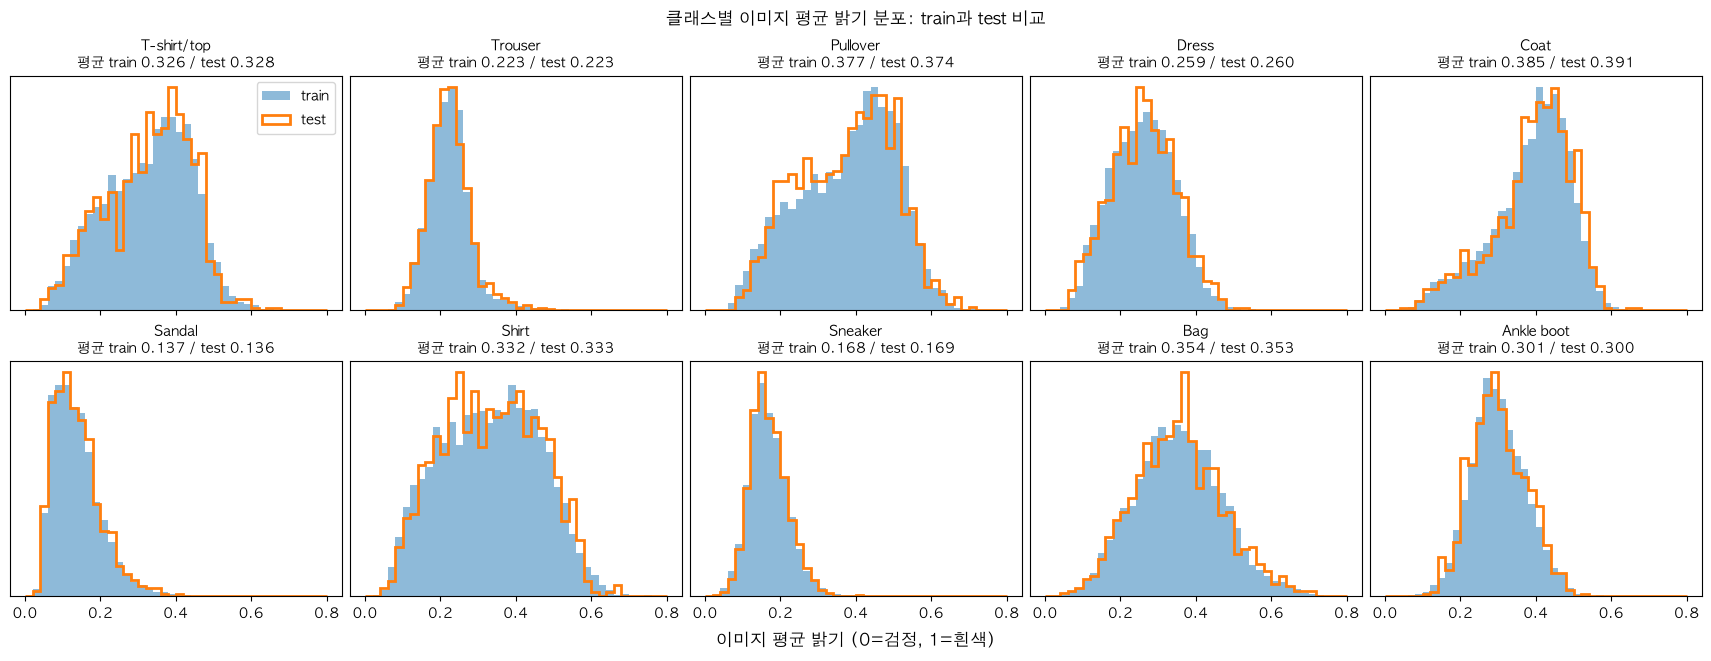

In [20]:
# 이미지 한 장의 평균 밝기 = 784개(28x28) 픽셀 값의 평균 (0=검정, 1=흰색)
train_brightness = train_float.mean(dim=(1, 2))
test_brightness = test_float.mean(dim=(1, 2))

bins = np.linspace(0, 0.8, 41)
fig, axes = plt.subplots(2, 5, figsize=(17, 6.5), sharex=True, layout='constrained')
for c, ax in enumerate(axes.flat):
    train_values = train_brightness[train_labels == c].numpy()
    test_values = test_brightness[test_labels == c].numpy()
    # density=True: 막대 면적의 합을 1로 맞춰, 개수가 다른 train(6,000장)과 test(1,000장)를 같은 눈금으로 비교
    ax.hist(train_values, bins=bins, density=True, alpha=0.5, label='train')
    ax.hist(test_values, bins=bins, density=True, histtype='step', linewidth=2, label='test')
    ax.set_title(f'{CLASS_NAMES[c]}\n평균 train {train_values.mean():.3f} / test {test_values.mean():.3f}', fontsize=10)
    ax.set_yticks([])
axes[0, 0].legend()
fig.supxlabel('이미지 평균 밝기 (0=검정, 1=흰색)')
fig.suptitle('클래스별 이미지 평균 밝기 분포: train과 test 비교')
save_fig(fig, '1-1_split_brightness')
plt.show()

**인사이트**
- 모든 클래스에서 train(파란 막대)과 test(주황 선)의 분포 모양이 거의 겹친다.
- 클래스별 평균 밝기 차이는 가장 큰 Coat도 0.006(train 0.385, test 0.391)이다.
- test 선이 더 들쭉날쭉한 것은 test 이미지 수가 train의 6분의 1이라서 생기는 차이이다.

**결론**
- train과 test는 같은 분포에서 나온 데이터로 볼 수 있다.
- 따라서 test를 생성 이미지 평가의 기준 분포로 사용한다.
    - FID(생성 이미지 묶음과 실제 이미지 묶음의 분포 거리, 5-1에서 설명)를 계산할 때와, 눈으로 비교할 때 모두 test를 기준으로 쓴다.

### 1-2. 기본 sanity check (데이터가 예상한 형태인지 확인하는 기본 점검)
- 이미지 텐서의 모양, 자료형, 픽셀 값 범위, 배경(값 0) 픽셀 비율을 확인한다.
- 관례대로 쓸 전처리 `v2.Normalize(mean=[0.5], std=[0.5])`가 픽셀 값을 [-1, 1]로 정확히 옮기는지 확인한다.
    - Generator의 마지막 활성화 함수 Tanh의 출력 범위가 [-1, 1]이므로, 실제 이미지도 같은 범위여야 한다.
- 전처리는 torchvision의 새 전처리 모듈인 `torchvision.transforms.v2`로 작성한다.
    - `v2.ToImage()`: 이미지를 텐서로 바꾼다. 값은 0~255 정수 그대로 둔다.
    - `v2.ToDtype(torch.float32, scale=True)`: 실수로 바꾸면서 255로 나눠 0~1 범위로 만든다.
    - `v2.Normalize(mean=[0.5], std=[0.5])`: (x - 0.5) / 0.5 를 계산해 -1~1 범위로 옮긴다.
    - 예전 방식(v1)의 `ToTensor()` 한 단계가 v2에서는 `ToImage()`와 `ToDtype(..., scale=True)` 두 단계로 나뉜다.

In [21]:
# 학습 코드에서 쓸 전처리: [0, 255] -> ToImage -> ToDtype(scale=True) -> [0, 1] -> Normalize(0.5, 0.5) -> [-1, 1]
gan_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.5], std=[0.5]),
])


def summarize_split(dataset, images):
    """한 split의 sanity check 항목을 계산한다."""
    # 전체 이미지에 transform을 하나씩 적용하면 느리므로, 같은 공식 (x - 0.5) / 0.5 로 한 번에 계산
    normalized = (images.float() / 255 - 0.5) / 0.5
    # 처음 1,000장은 실제 transform 결과와 공식 결과가 같은지 검증
    transformed = torch.stack([gan_transform(dataset[i][0]) for i in range(1000)]).squeeze(1)
    assert torch.allclose(transformed, normalized[:1000], atol=1e-6)
    return [
        str(tuple(images.shape)),
        str(images.dtype),
        images.min().item(),
        images.max().item(),
        f'{(images == 0).float().mean().item():.1%}',
        f'{(images.amin(dim=(1, 2)) == 0).float().mean().item():.1%}',
        f'{(images.amax(dim=(1, 2)) == 255).float().mean().item():.1%}',
        f'{normalized.min().item():.1f}',
        f'{normalized.max().item():.1f}',
    ]


items = ['텐서 모양 (이미지 수, 높이, 너비)', '자료형', '픽셀 최솟값', '픽셀 최댓값',
         '배경(값 0) 픽셀 비율', '배경(값 0)이 있는 이미지 비율', '가장 밝은 픽셀이 255인 이미지 비율',
         '정규화 후 최솟값', '정규화 후 최댓값']
train_summary = summarize_split(train_dataset, train_images)
test_summary = summarize_split(test_dataset, test_images)
show_table(['항목', 'train', 'test'], [[item, a, b] for item, a, b in zip(items, train_summary, test_summary)])

| 항목 | train | test |
| --- | --- | --- |
| 텐서 모양 (이미지 수, 높이, 너비) | (60000, 28, 28) | (10000, 28, 28) |
| 자료형 | torch.uint8 | torch.uint8 |
| 픽셀 최솟값 | 0 | 0 |
| 픽셀 최댓값 | 255 | 255 |
| 배경(값 0) 픽셀 비율 | 50.2% | 50.0% |
| 배경(값 0)이 있는 이미지 비율 | 100.0% | 100.0% |
| 가장 밝은 픽셀이 255인 이미지 비율 | 91.6% | 91.9% |
| 정규화 후 최솟값 | -1.0 | -1.0 |
| 정규화 후 최댓값 | 1.0 | 1.0 |

**인사이트**
- 이미지는 28x28 크기의 흑백 이미지이고, 자료형은 0~255 정수를 담는 uint8이다.
- 픽셀 값은 0~255 범위를 끝까지 사용한다.
- 모든 이미지에 값이 정확히 0인 검은 배경이 있고, 전체 픽셀의 약 50%가 배경이다.
- 이미지의 약 92%는 가장 밝은 픽셀이 255이다.
    - 이미지마다 가장 밝은 부분이 255가 되도록 밝기가 맞춰져 있는 것으로 보인다.
- v2 전처리(`ToImage` → `ToDtype` → `Normalize`)를 적용하면 값이 정확히 -1.0~1.0이 된다.
    - 실제 v2 전처리 결과와 공식으로 계산한 결과도 일치했다.

**결론**
- 정규화는 아래 v2 전처리를 사용하고, Generator의 마지막 활성화 함수는 Tanh를 사용한다.
    - `v2.ToImage()` → `v2.ToDtype(torch.float32, scale=True)` → `v2.Normalize(mean=[0.5], std=[0.5])`
- 픽셀의 절반이 배경이므로, Generator는 Tanh 출력의 -1 근처 값(검은 배경)을 정확히 만들어야 한다.
    - 학습 중에는 생성 이미지의 배경이 회색으로 뜨지 않는지 확인한다.
- 대부분의 이미지가 0~255 범위를 꽉 채우므로, 밝기를 바꾸는 증강은 실제 데이터에 드문 이미지를 만든다. (2번 결론과 함께 판단)

### 1-3. 이미지 육안 확인
- train과 test 각각에서 클래스마다 무작위로 10장을 뽑아 그리드로 본다. (seed 고정)

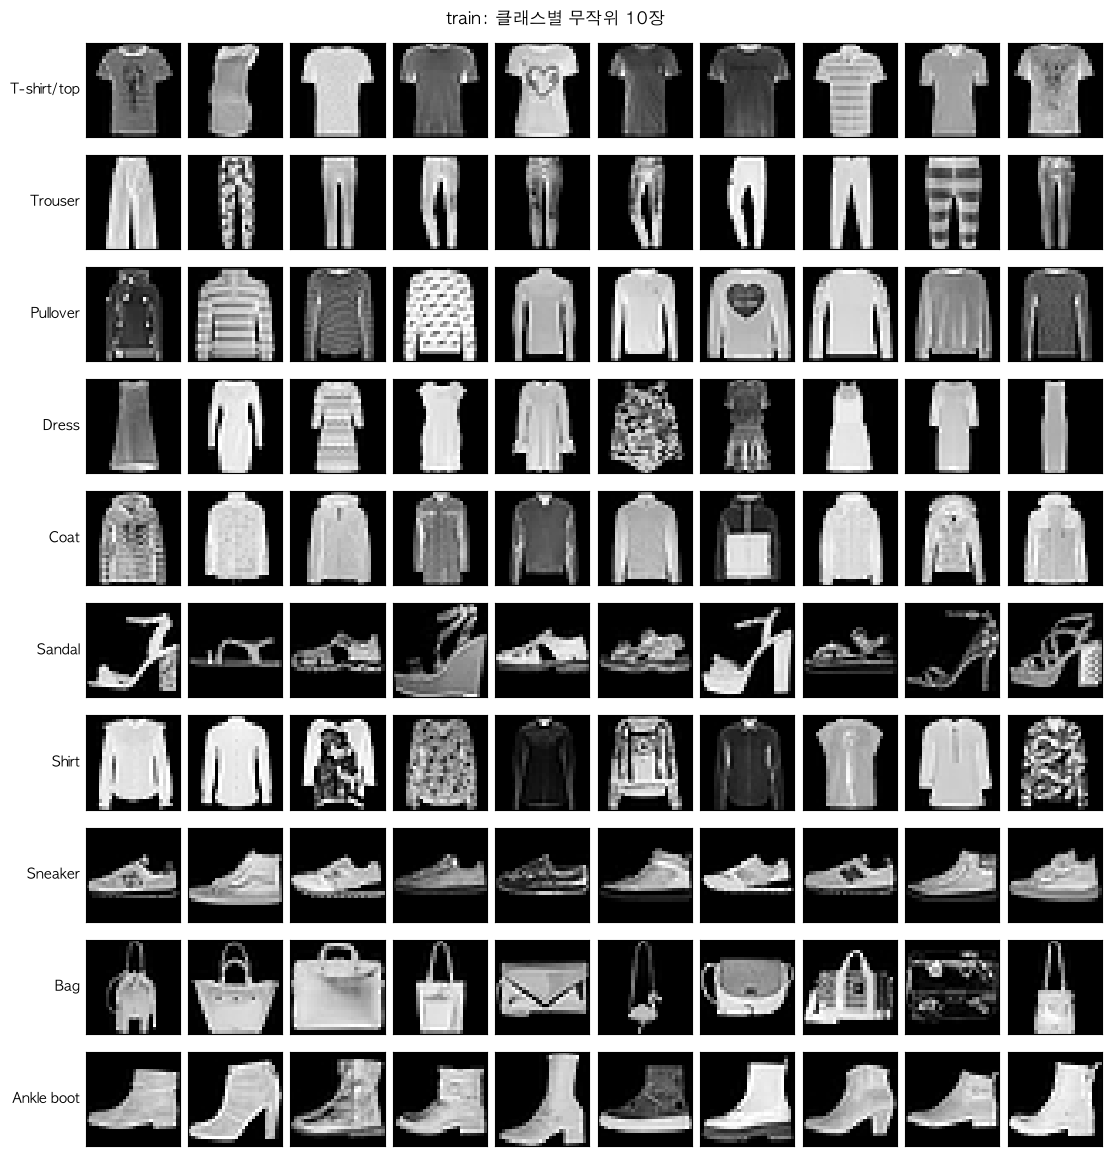

In [22]:
def plot_class_grid(images, labels, title, n_per_class=10):
    """클래스마다 무작위로 n_per_class장씩 뽑아 (클래스 수 x n_per_class) 그리드로 그린다."""
    rng = np.random.default_rng(SEED)  # 셀을 다시 실행해도 같은 이미지가 뽑히도록 고정
    fig, axes = plt.subplots(NUM_CLASSES, n_per_class, figsize=(n_per_class * 1.1, NUM_CLASSES * 1.15),
                             layout='constrained')
    for c in range(NUM_CLASSES):
        chosen = rng.choice(torch.where(labels == c)[0].numpy(), size=n_per_class, replace=False)
        for j, idx in enumerate(chosen):
            axes[c, j].imshow(images[idx], cmap='gray', vmin=0, vmax=255)
            axes[c, j].set_xticks([])
            axes[c, j].set_yticks([])
        axes[c, 0].set_ylabel(CLASS_NAMES[c], rotation=0, ha='right', va='center', fontsize=10)
    fig.suptitle(title)
    return fig


fig = plot_class_grid(train_images, train_labels, 'train: 클래스별 무작위 10장')
save_fig(fig, '1-3_grid_train')
plt.show()

**인사이트**
- 모든 물체가 똑바로 세워진 상태로 이미지 가운데에 놓여 있다.
- 신발 세 클래스(Sandal, Sneaker, Ankle boot)는 대부분 앞코가 왼쪽을 향한다. (2-1의 평균 이미지에서 더 분명하게 보인다)
- 클래스 안에서도 모양이 다양하다.
    - T-shirt/top에는 민소매 상의가 섞여 있다.
    - Sandal은 납작한 샌들부터 굽이 높은 샌들까지 있다.
    - Bag은 손잡이와 가방 형태가 제각각이다.
- Shirt에는 반소매 셔츠도 있어, T-shirt/top과 비슷해 보이는 이미지가 있다.

**결론**
- 물체의 자세와 위치가 정해진 방식으로 정렬된 데이터이다. 이 정렬을 깨는 증강은 실제 데이터에 없는 이미지를 만든다. (2번에서 수치로 확인)
- 생성 이미지를 눈으로 평가할 때 이 그리드와 나란히 놓고 비교한다.

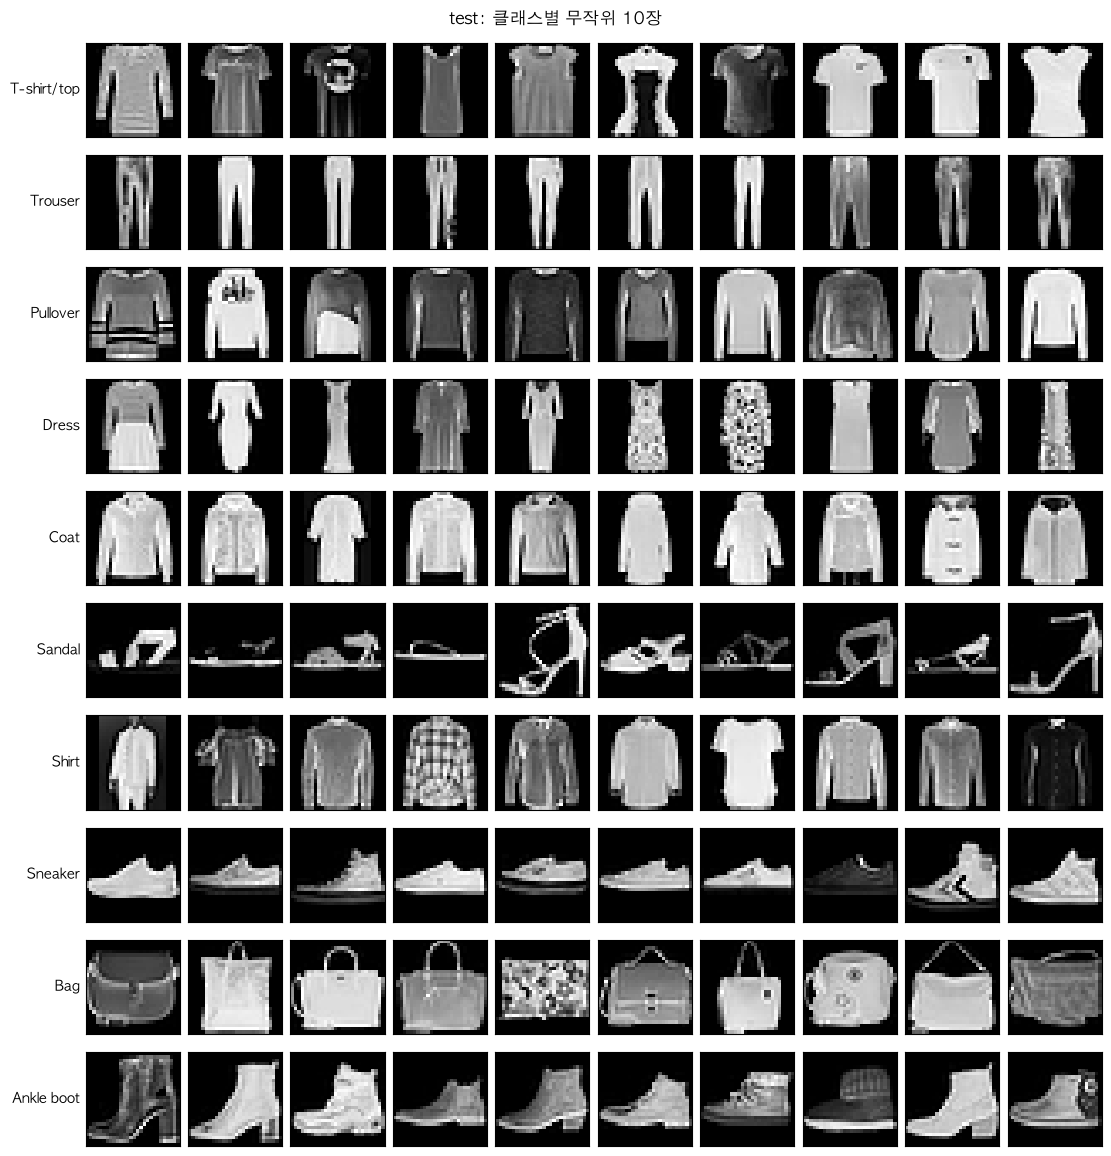

In [23]:
fig = plot_class_grid(test_images, test_labels, 'test: 클래스별 무작위 10장')
save_fig(fig, '1-3_grid_test')
plt.show()

**인사이트**
- test 이미지도 train과 같은 방식으로 정렬되어 있다. (가운데 배치, 똑바로 세운 자세, 신발 앞코는 왼쪽)
- 클래스 안의 다양성도 train과 비슷하다. 예를 들어 T-shirt/top에 민소매 상의와 긴소매로 보이는 상의가 함께 있다.
- Shirt에는 반소매 셔츠와 체크무늬 셔츠가 있어, 다른 상의 클래스와 구분하기 쉽지 않다.

**결론**
- 눈으로 봐도 train과 test의 차이는 보이지 않는다. 1-1의 통계 비교 결과와 일치한다.
- 상의 클래스(T-shirt/top, Pullover, Coat, Shirt)는 실제 이미지끼리도 비슷해 보인다.
    - 생성 결과에서 이 클래스들이 라벨대로 구분되어 나오는지 따로 확인해야 한다. (3번에서 수치로 확인)

## 2. 공간 구조
- 이미지 안에서 물체가 어디에, 어떤 방향과 크기로 놓여 있는지 확인한다.
- 목적: 회전, 크롭, 좌우 반전, 밝기 조절 증강이 이 데이터에 맞는지 판단하고 증강 정책을 정한다.
    - GAN(Generative Adversarial Network, 생성적 적대 신경망)에서 실제 이미지에만 증강을 적용하면, Generator가 증강된 모양까지 따라 배운다.
    - 그래서 증강이 실제 데이터에 없는 모양을 만드는지가 판단 기준이다.

### 2-1. 클래스별 평균 / 표준편차 이미지

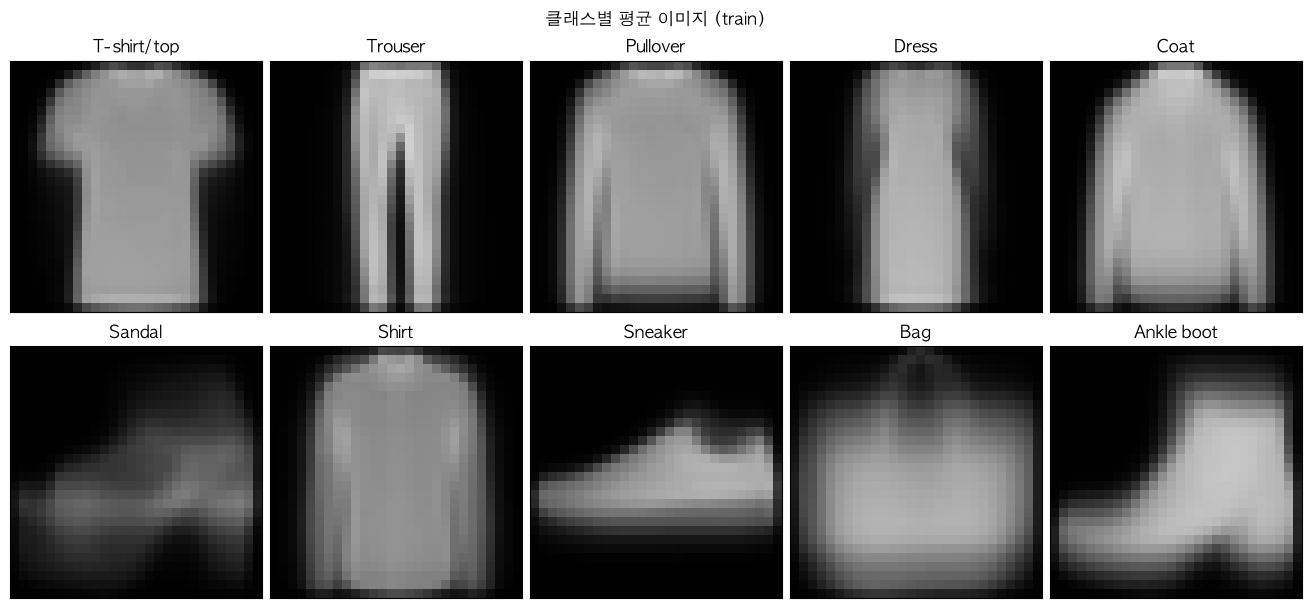

In [24]:
# 클래스별 평균 이미지: 같은 위치의 픽셀 값을 클래스 안의 모든 train 이미지에 대해 평균
class_mean = torch.stack([train_float[train_labels == c].mean(dim=0) for c in range(NUM_CLASSES)])

fig, axes = plt.subplots(2, 5, figsize=(13, 6), layout='constrained')
for c, ax in enumerate(axes.flat):
    ax.imshow(class_mean[c], cmap='gray', vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[c])
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle('클래스별 평균 이미지 (train)')
save_fig(fig, '2-1_class_mean')
plt.show()

**인사이트**
- 평균 이미지인데도 흐릿하지 않고 클래스 모양이 뚜렷하다.
    - 물체의 위치, 크기, 방향이 이미지마다 거의 같다는 뜻이다.
- 상의 클래스(T-shirt/top, Pullover, Coat, Shirt)는 평균 모양이 서로 비슷하다. 눈에 띄는 차이는 소매 길이 정도이다.
- 신발 세 클래스는 모두 앞코가 왼쪽, 뒤꿈치와 발목 부분이 오른쪽에 있다.
- Bag은 다른 클래스보다 평균 이미지가 흐릿하다. 가방 모양이 제각각이기 때문이다.

**결론**
- 물체가 똑바로 세워진 자세로 정렬되어 있으므로, 회전 증강은 실제 데이터에 없는 기울어진 이미지를 만든다. 회전 증강은 사용하지 않는다.
- 생성 이미지로도 클래스별 평균 이미지를 그려 이 그림과 비교하면, Generator가 클래스별 기본 모양을 배웠는지 빠르게 확인할 수 있다.

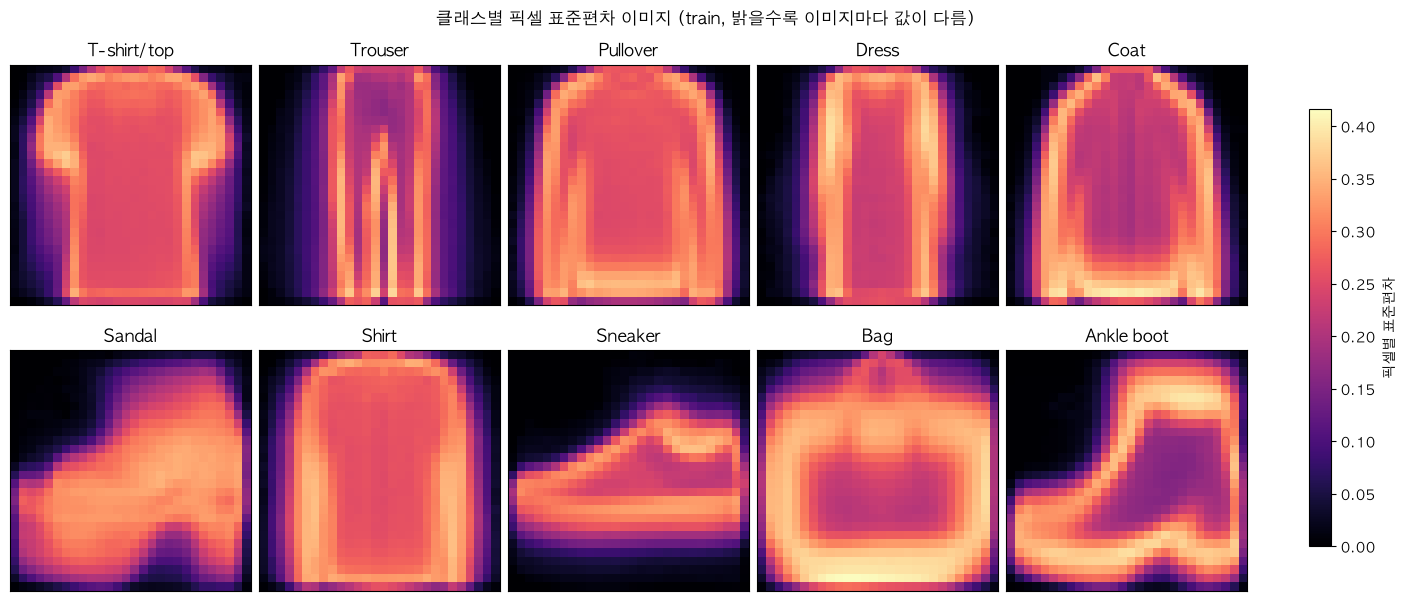

In [25]:
# 픽셀별 표준편차 이미지: 같은 위치의 픽셀 값이 클래스 안에서 얼마나 들쭉날쭉한지 (밝을수록 이미지마다 다름)
class_std = torch.stack([train_float[train_labels == c].std(dim=0) for c in range(NUM_CLASSES)])

fig, axes = plt.subplots(2, 5, figsize=(14, 6), layout='constrained')
for c, ax in enumerate(axes.flat):
    image = ax.imshow(class_std[c], cmap='magma', vmin=0, vmax=class_std.max())
    ax.set_title(CLASS_NAMES[c])
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(image, ax=axes, shrink=0.8, label='픽셀별 표준편차')
fig.suptitle('클래스별 픽셀 표준편차 이미지 (train, 밝을수록 이미지마다 값이 다름)')
save_fig(fig, '2-1_class_std')
plt.show()

**인사이트**
- 표준편차가 큰(밝은) 곳은 주로 물체의 테두리이다.
    - 소매 길이, 옷 폭, 신발 높이가 이미지마다 조금씩 달라서 테두리 위치가 바뀌기 때문이다.
- 물체 안쪽은 표준편차가 중간 정도이다. 옷 색과 무늬가 이미지마다 다르기 때문이다.
- 이미지 구석(배경 영역)은 거의 검은색이다. 거의 모든 이미지에서 같은 위치가 배경이라는 뜻이다.
- Bag과 Sandal은 밝은 영역이 넓다. 두 클래스는 모양 변화가 큰 편이다.

**결론**
- 클래스마다 모양이 바뀌는 부분(테두리)은 정해져 있고, 배경 위치는 거의 고정되어 있다.
    - 크롭이나 이동 증강은 이 배경 위치를 바꾸므로, 실제 데이터에 없는 배치를 만든다. (2-3에서 함께 판단)
- Bag과 Sandal은 모양 변화가 커서, Generator가 다양한 모양을 만들어 내는지 지켜볼 후보이다. (3번에서 확인)

### 2-2. 좌우 대칭성
- 클래스 평균 이미지와, 그것을 좌우로 뒤집은 이미지가 얼마나 다른지 점수로 비교한다.
    - 좌우 비대칭 점수 = 두 이미지의 픽셀 차이 합 ÷ (2 × 평균 이미지의 밝기 합)
    - 0이면 완전히 좌우 대칭이고, 1이면 뒤집었을 때 전혀 겹치지 않는다.

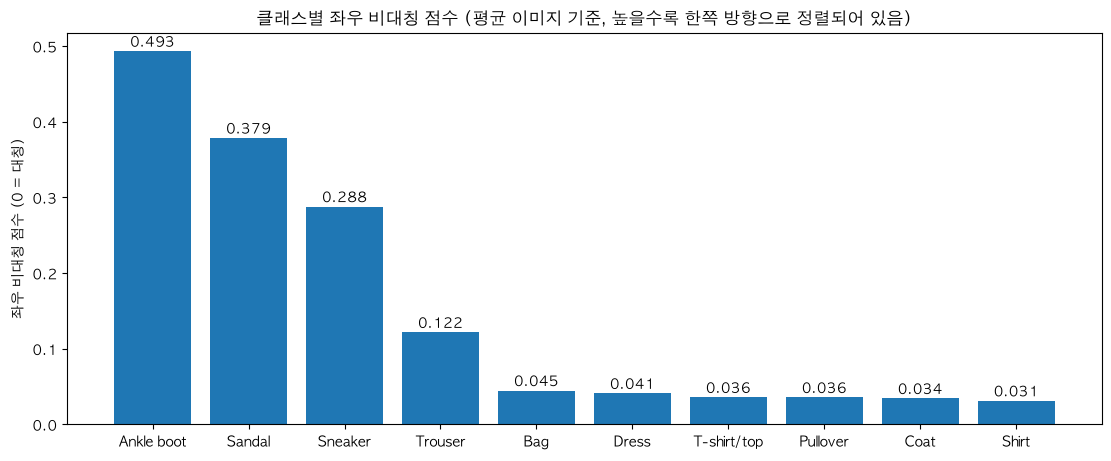

In [26]:
# dims=[2]: 너비 방향(좌우)으로 뒤집기
flipped_mean = torch.flip(class_mean, dims=[2])
asymmetry = (class_mean - flipped_mean).abs().sum(dim=(1, 2)) / (2 * class_mean.sum(dim=(1, 2)))

order = torch.argsort(asymmetry, descending=True).tolist()
fig, ax = plt.subplots(figsize=(11, 4.5), layout='constrained')
bars = ax.bar([CLASS_NAMES[c] for c in order], asymmetry[order].numpy())
ax.bar_label(bars, fmt='%.3f')
ax.set_ylabel('좌우 비대칭 점수 (0 = 대칭)')
ax.set_title('클래스별 좌우 비대칭 점수 (평균 이미지 기준, 높을수록 한쪽 방향으로 정렬되어 있음)')
save_fig(fig, '2-2_asymmetry')
plt.show()

**인사이트**
- 신발 세 클래스의 점수가 확연히 높다: Ankle boot 0.493, Sandal 0.379, Sneaker 0.288
    - 평균 이미지에서 본 것처럼, 신발은 앞코가 왼쪽을 향하도록 한 방향으로 정렬되어 있다.
- Trouser는 0.122로 다른 옷보다 높지만, 신발보다는 훨씬 낮다.
- 나머지 옷과 가방은 0.031~0.045로 거의 좌우 대칭이다.

**결론**
- 신발 클래스에는 좌우 반전 증강을 쓰지 않는다.
    - 반전하면 앞코가 오른쪽을 향한 신발이 생기는데, 이런 신발은 실제 데이터(test 포함)에 거의 없다.
    - 실제 이미지에만 반전을 적용하면, Generator가 오른쪽을 향한 신발도 만들게 되어 test 기준 FID가 나빠진다.
- 옷과 가방은 평균 이미지 기준으로 좌우 대칭이라, 반전해도 분포가 크게 바뀌지 않을 가능성이 높다.
    - 다만 데이터가 클래스당 6,000장으로 충분하므로, 반전 증강 없이 시작한다.
    - Discriminator가 학습 데이터에 과적합하는 징후가 보이면, 대칭 클래스에 한해 반전 증강을 실험한다.

### 2-3. 객체 위치와 크기
- 값이 0이 아닌 픽셀은 '객체 영역'이라고 정의한다. (1-2에서 모든 이미지에 값 0인 배경이 있음을 확인)
- bounding box(객체를 감싸는 가장 작은 직사각형)의 크기, 무게중심, 점유 면적을 클래스별로 정리한다.

In [27]:
train_mask = train_images > 0                # 객체 픽셀이면 True
rows_with_object = train_mask.any(dim=2)     # (N, 28): 각 가로줄에 객체 픽셀이 하나라도 있는지
cols_with_object = train_mask.any(dim=1)     # (N, 28): 각 세로줄에 객체 픽셀이 하나라도 있는지


def first_and_last(has_object):
    """True가 처음 나오는 인덱스와 마지막으로 나오는 인덱스를 구한다."""
    first = has_object.int().argmax(dim=1)
    last = has_object.shape[1] - 1 - has_object.flip(dims=[1]).int().argmax(dim=1)
    return first, last


top, bottom = first_and_last(rows_with_object)
left, right = first_and_last(cols_with_object)
bbox_height = (bottom - top + 1).float()
bbox_width = (right - left + 1).float()
long_side = torch.maximum(bbox_height, bbox_width)
train_object_ratio = train_mask.float().mean(dim=(1, 2))  # 점유 면적: 784픽셀 중 객체 픽셀 비율

rows = []
for c, name in enumerate(CLASS_NAMES):
    in_class = train_labels == c
    rows.append([name,
                 f'{bbox_width[in_class].median():.0f}',
                 f'{bbox_height[in_class].median():.0f}',
                 f'{(long_side[in_class] == 28).float().mean():.1%}',
                 f'{train_object_ratio[in_class].median():.1%}'])
rows.append(['**전체**', f'{bbox_width.median():.0f}', f'{bbox_height.median():.0f}',
             f'{(long_side == 28).float().mean():.1%}', f'{train_object_ratio.median():.1%}'])
show_table(['클래스', 'bounding box 너비 중앙값 (픽셀)', 'bounding box 높이 중앙값 (픽셀)',
            '긴 변이 28픽셀(이미지 끝에서 끝까지)인 이미지 비율', '점유 면적 중앙값'], rows)

| 클래스 | bounding box 너비 중앙값 (픽셀) | bounding box 높이 중앙값 (픽셀) | 긴 변이 28픽셀(이미지 끝에서 끝까지)인 이미지 비율 | 점유 면적 중앙값 |
| --- | --- | --- | --- | --- |
| T-shirt/top | 22 | 28 | 98.5% | 59.9% |
| Trouser | 11 | 28 | 98.7% | 33.3% |
| Pullover | 21 | 28 | 96.0% | 64.5% |
| Dress | 15 | 28 | 99.0% | 42.7% |
| Coat | 20 | 28 | 96.3% | 60.7% |
| Sandal | 28 | 15 | 99.9% | 31.5% |
| Shirt | 21 | 28 | 97.0% | 63.5% |
| Sneaker | 28 | 13 | 99.7% | 32.9% |
| Bag | 28 | 26 | 98.6% | 58.7% |
| Ankle boot | 28 | 21 | 99.3% | 47.7% |
| **전체** | 22 | 28 | 98.3% | 51.3% |

**인사이트**
- 전체 이미지의 98.3%에서 bounding box의 긴 변이 28픽셀이다. 물체가 이미지 한쪽 끝에서 반대쪽 끝까지 꽉 차 있다.
    - 상의, 바지, 원피스는 높이가 28픽셀(위아래로 꽉 참)이다.
    - 신발과 가방은 너비가 28픽셀(좌우로 꽉 참)이다.
- 짧은 변의 길이는 클래스마다 다르다: Trouser 너비 11픽셀, Sneaker 높이 13픽셀, Sandal 높이 15픽셀
- 점유 면적의 중앙값은 상의가 60~65%로 크고, Trouser, Sandal, Sneaker는 31~33%로 작다.

**결론**
- 물체의 긴 변을 28픽셀에 맞춰 넣은 데이터이다. 크롭이나 이동 증강을 하면 물체 끝이 이미지 밖으로 잘린다.
- 실제 데이터에는 잘린 물체가 거의 없으므로, 크롭, 이동, 확대·축소 증강은 사용하지 않는다.
- 생성 이미지에서도 물체가 이미지 끝까지 닿아 있는지가, 형태를 잘 배웠는지 보는 기준이 된다.

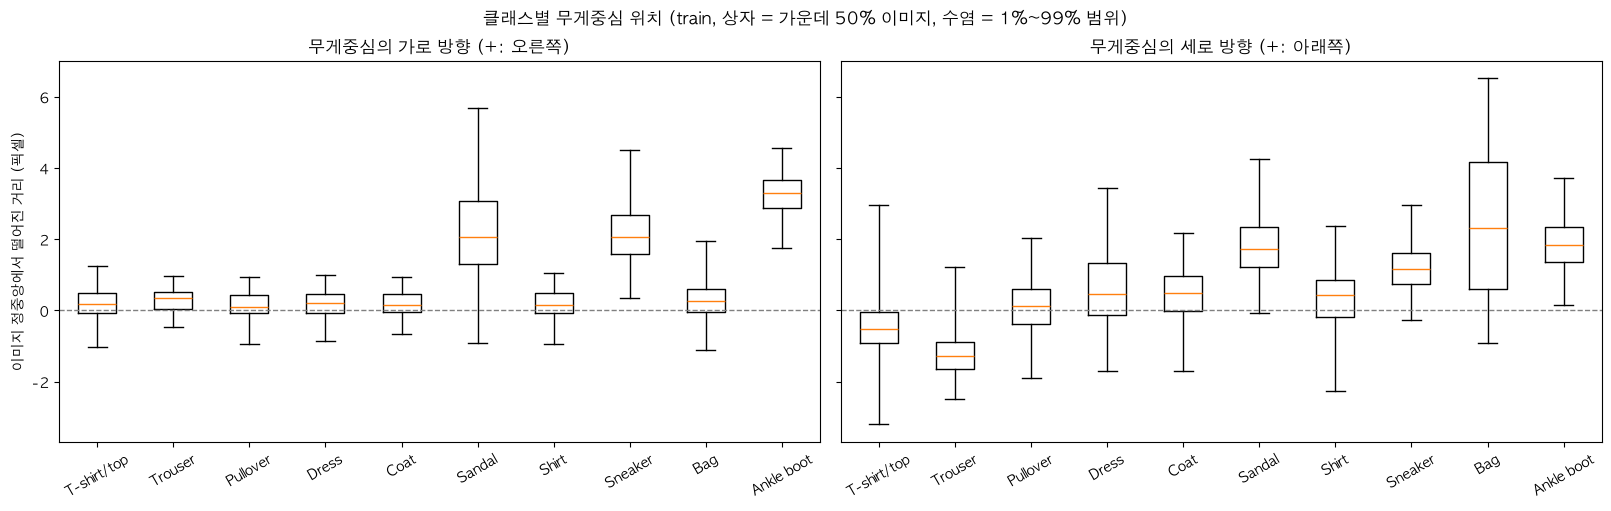

In [28]:
# 무게중심 = 픽셀 밝기를 가중치로 한 평균 위치 (밝은 픽셀일수록 위치 계산에 크게 반영)
positions = torch.arange(28).float()
total_brightness = train_float.sum(dim=(1, 2))
centroid_x = (train_float.sum(dim=1) * positions).sum(dim=1) / total_brightness
centroid_y = (train_float.sum(dim=2) * positions).sum(dim=1) / total_brightness

# 이미지 정중앙(13.5)에서 몇 픽셀 떨어져 있는지
offsets = {'가로 방향 (+: 오른쪽)': centroid_x - 13.5, '세로 방향 (+: 아래쪽)': centroid_y - 13.5}

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True, layout='constrained')
for ax, (direction, offset) in zip(axes, offsets.items()):
    # 상자: 가운데 50% 이미지가 있는 범위, 수염: 1%~99% 범위
    ax.boxplot([offset[train_labels == c].numpy() for c in range(NUM_CLASSES)],
               tick_labels=CLASS_NAMES, whis=(1, 99), showfliers=False)
    ax.axhline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_title(f'무게중심의 {direction}')
    ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('이미지 정중앙에서 떨어진 거리 (픽셀)')
fig.suptitle('클래스별 무게중심 위치 (train, 상자 = 가운데 50% 이미지, 수염 = 1%~99% 범위)')
save_fig(fig, '2-3_centroid')
plt.show()

**인사이트**
- 옷 여섯 클래스(T-shirt/top, Trouser, Pullover, Dress, Coat, Shirt)와 Bag은 가로 방향 상자(가운데 50% 이미지)가 정중앙에서 1픽셀 이내에 있다.
- 신발 세 클래스는 무게중심이 오른쪽으로 2~3픽셀 치우쳐 있다. 무거운 뒤꿈치와 발목 부분이 오른쪽에 있기 때문이다.
- 세로 방향은 클래스마다 치우치는 방향이 다르다.
    - 신발과 Bag은 아래쪽으로 치우쳐 있다. 신발 바닥과 가방 몸통이 아래쪽에 있기 때문이다.
    - Trouser는 위쪽으로 치우쳐 있다. 허리 부분이 넓고 다리 사이가 비어 있기 때문이다.
- Bag을 제외하면 상자의 길이(가운데 50% 범위)가 대부분 2픽셀 이내로 좁다. Bag은 손잡이 크기에 따라 세로 위치가 넓게 퍼진다.

**결론**
- 물체 위치는 무작위로 흩어져 있지 않고, 클래스마다 거의 정해진 자리에 놓여 있다.
- 2-3의 bounding box 결과와 함께 보면, 이동 증강은 실제 데이터에 없는 위치를 만든다. 이동 증강은 사용하지 않는다.
- 생성 이미지의 무게중심도 같은 방식으로 계산해 이 분포와 비교하면, 위치가 틀어진 생성 결과를 찾아낼 수 있다.

## 3. 클래스 내 다양성과 클래스 간 유사도
- 목적: 서로 헷갈리기 쉬운 클래스와 모양이 다양한 클래스를 찾아, 학습 중 집중해서 지켜볼 클래스를 정한다.

### 3-1. 클래스 내 다양성
- 이미지를 784개 숫자로 된 벡터로 보고, 각 이미지와 자기 클래스 평균 이미지 사이의 유클리드 거리(L2 거리, 두 벡터 사이의 직선 거리)를 잰다.
- 거리가 대체로 크면, 그 클래스 안에 서로 다른 모양이 많다는 뜻이다.

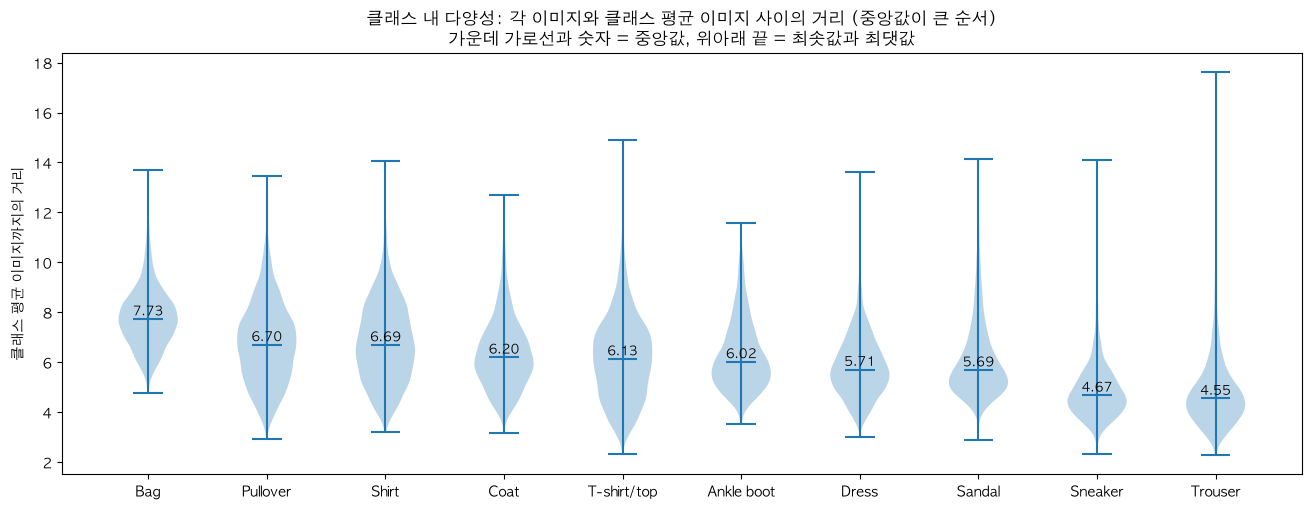

In [29]:
# 각 이미지와 자기 클래스 평균 이미지 사이의 유클리드 거리
train_dist_to_mean = (train_float - class_mean[train_labels]).flatten(1).norm(dim=1)

medians = torch.stack([train_dist_to_mean[train_labels == c].median() for c in range(NUM_CLASSES)])
order = torch.argsort(medians, descending=True).tolist()

fig, ax = plt.subplots(figsize=(13, 5), layout='constrained')
ax.violinplot([train_dist_to_mean[train_labels == c].numpy() for c in order], showmedians=True)
for x, c in enumerate(order, start=1):
    ax.text(x, medians[c].item() + 0.15, f'{medians[c]:.2f}', ha='center', fontsize=9)
ax.set_xticks(range(1, NUM_CLASSES + 1), [CLASS_NAMES[c] for c in order])
ax.set_ylabel('클래스 평균 이미지까지의 거리')
ax.set_title('클래스 내 다양성: 각 이미지와 클래스 평균 이미지 사이의 거리 (중앙값이 큰 순서)\n'
             '가운데 가로선과 숫자 = 중앙값, 위아래 끝 = 최솟값과 최댓값')
save_fig(fig, '3-1_distance_to_mean')
plt.show()

**인사이트**
- Bag의 중앙값이 7.73으로 가장 크다. 가방은 모양이 가장 다양한 클래스이다.
- 그다음은 Pullover(6.70)와 Shirt(6.69)이다.
- Trouser(4.55)와 Sneaker(4.67)는 중앙값이 가장 작다. 서로 비슷한 모양의 이미지가 많다.
    - 다만 Trouser는 최댓값이 약 17.6으로 가장 크다. 대부분은 비슷하지만, 아주 특이한 바지가 일부 있다. (4-2에서 확인)
- 이 거리는 모양뿐 아니라 밝기 차이에도 영향을 받는다. 모양이 같아도 옷 색이 아주 밝거나 어두우면 거리가 커진다.

**결론**
- Bag, Pullover, Shirt는 다양성이 커서, 생성 결과의 다양성이 실제보다 줄었는지 집중해서 확인할 클래스이다.
- 생성 이미지로 같은 거리 분포를 그렸을 때 실제보다 분포 폭이 좁으면, 다양성이 부족하다는 신호이다.

### 3-2. 클래스 간 유사도
- 클래스 평균 이미지끼리 코사인 유사도(두 벡터가 같은 방향을 가리키는 정도, 1이면 모양이 같음)를 계산한다.
- 주성분 분석(PCA, 데이터가 가장 넓게 퍼진 방향을 찾아 차원을 줄이는 방법)으로 이미지를 2차원에 펼쳐, 클래스끼리 얼마나 겹치는지 본다.

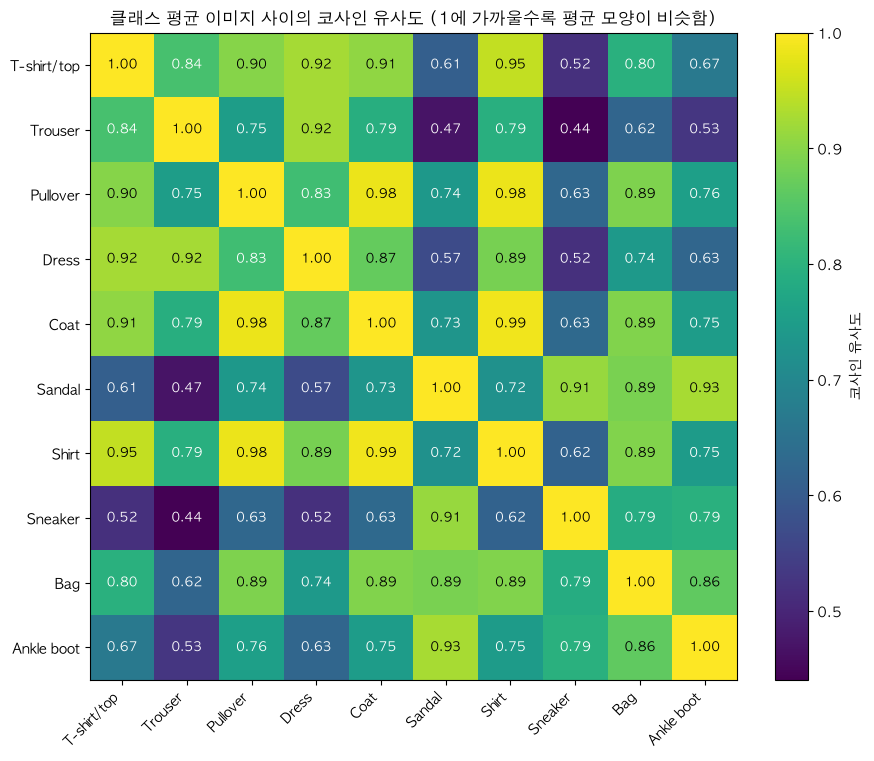

In [30]:
# 평균 이미지를 784차원 벡터로 펼치고, 길이 1로 맞춘 뒤 서로 내적하면 코사인 유사도
mean_vectors = class_mean.flatten(1)
unit_vectors = mean_vectors / mean_vectors.norm(dim=1, keepdim=True)
cosine = (unit_vectors @ unit_vectors.T).numpy()

fig, ax = plt.subplots(figsize=(9, 7.5), layout='constrained')
image = ax.imshow(cosine, cmap='viridis', vmin=cosine.min(), vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        text_color = 'black' if cosine[i, j] > 0.85 else 'white'
        ax.text(j, i, f'{cosine[i, j]:.2f}', ha='center', va='center', fontsize=9, color=text_color)
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
fig.colorbar(image, ax=ax, label='코사인 유사도')
ax.set_title('클래스 평균 이미지 사이의 코사인 유사도 (1에 가까울수록 평균 모양이 비슷함)')
save_fig(fig, '3-2_cosine_similarity')
plt.show()

**인사이트**
- 상의 클래스끼리 유사도가 가장 높다.
    - Coat와 Shirt 0.99, Pullover와 Coat 0.98, Pullover와 Shirt 0.98
    - T-shirt/top과 Shirt 0.95
- 신발끼리도 높다: Sandal과 Ankle boot 0.93, Sandal과 Sneaker 0.91
- Trouser는 Dress(0.92), T-shirt/top(0.84)을 제외한 다른 클래스와 유사도가 낮다. Sneaker와는 0.44로 가장 낮다.
- 모든 값이 0.44 이상으로 높은 편이다.
    - 픽셀 값이 모두 0 이상이고, 물체가 공통으로 이미지 가운데에 있기 때문이다.
    - 그래서 값의 크기 자체보다 클래스 사이의 상대적인 순서를 봐야 한다.

**결론**
- Shirt, Coat, Pullover는 평균 모양이 거의 같아, 조건부 생성에서 서로 섞여 생성될 위험이 가장 크다.
- 이 세 클래스와 T-shirt/top은 학습 중 클래스별 생성 결과를 나란히 놓고, 라벨에 맞는 특징(소매 길이, 단추, 지퍼 등)이 나오는지 확인한다.

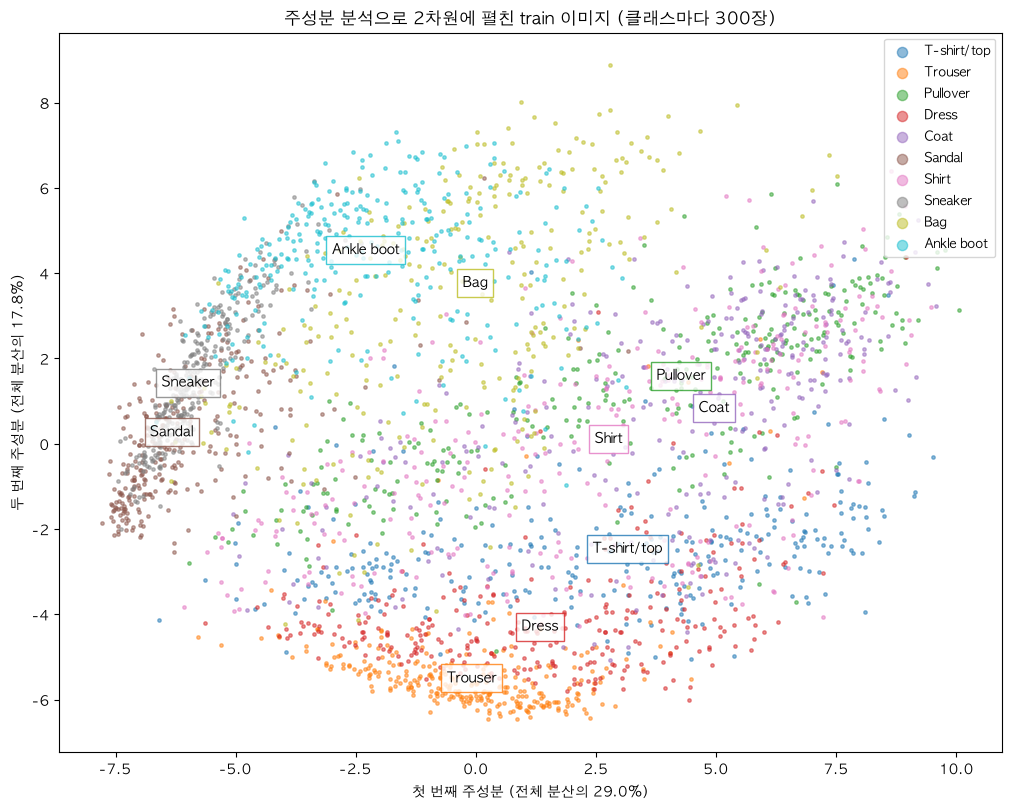

In [31]:
# 주성분 계산: train 전체 이미지의 공분산 행렬에서 분산이 가장 큰 두 방향(고유벡터)을 찾는다
train_vectors = train_float.flatten(1)
pixel_mean = train_vectors.mean(dim=0)
covariance = torch.cov(train_vectors.T)
eigenvalues, eigenvectors = torch.linalg.eigh(covariance)   # 고유값이 작은 것부터 정렬되어 나옴
components = eigenvectors[:, [-1, -2]]                      # 가장 큰 두 방향
explained = eigenvalues[[-1, -2]] / eigenvalues.sum()       # 각 방향이 설명하는 분산 비율

# 그림이 너무 빽빽하지 않도록 클래스마다 300장만 뽑아 표시
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(10, 8), layout='constrained')
label_positions = []
for c in range(NUM_CLASSES):
    chosen = rng.choice(torch.where(train_labels == c)[0].numpy(), size=300, replace=False)
    projected = (train_vectors[chosen] - pixel_mean) @ components
    ax.scatter(projected[:, 0], projected[:, 1], s=6, alpha=0.5, color=plt.cm.tab10(c), label=CLASS_NAMES[c])
    # 클래스 이름은 해당 클래스 점들의 중앙에 표시 (앞서 붙인 이름과 겹치면 조금씩 아래로 내림)
    label_x, label_y = projected.median(dim=0).values.tolist()
    while any(abs(label_x - x) < 1.5 and abs(label_y - y) < 0.5 for x, y in label_positions):
        label_y -= 0.6
    label_positions.append((label_x, label_y))
    ax.text(label_x, label_y, CLASS_NAMES[c], fontsize=10, ha='center',
            bbox=dict(facecolor='white', alpha=0.8, edgecolor=plt.cm.tab10(c)))
ax.set_xlabel(f'첫 번째 주성분 (전체 분산의 {explained[0]:.1%})')
ax.set_ylabel(f'두 번째 주성분 (전체 분산의 {explained[1]:.1%})')
ax.legend(markerscale=3, loc='upper right', fontsize=9)
ax.set_title('주성분 분석으로 2차원에 펼친 train 이미지 (클래스마다 300장)')
save_fig(fig, '3-2_pca')
plt.show()

**인사이트**
- 두 주성분이 전체 분산의 46.8%(29.0% + 17.8%)를 설명한다. 2차원만으로도 큰 구조를 볼 수 있다.
- 신발 세 클래스는 왼쪽에 모여 옷과 뚜렷하게 떨어져 있다.
    - Ankle boot는 위쪽으로 조금 떨어져 있고, Sandal과 Sneaker는 많이 겹친다.
- Trouser는 아래쪽에 따로 모여 있고, Dress와 일부만 겹친다.
- 상의 클래스(T-shirt/top, Pullover, Coat, Shirt)는 오른쪽에서 넓게 겹친다.
    - Pullover와 Coat는 점들의 중앙 위치가 거의 같다.
    - Shirt는 상의 영역의 한가운데에 있어, 다른 상의 클래스 모두와 겹친다.
- Bag은 가운데 위쪽에 넓게 퍼져 있어, 여러 클래스와 조금씩 겹친다.

**결론**
- 2차원 투영에서도 상의 클래스는 잘 구분되지 않는다. 3-2의 유사도 결과와 같은 결론이다.
- 학습 중 집중해서 지켜볼 클래스
    - Shirt, Pullover, Coat, T-shirt/top: 서로 섞여 생성될 위험이 큼
    - Bag: 다양성이 가장 큼
    - Sandal, Sneaker: 신발끼리 겹치는 영역이 있음

## 4. 데이터 품질

### 4-1. 중복 및 누수 확인
- 누수란 test 이미지가 train에도 들어 있는 경우를 말한다.
    - 누수가 많으면, test를 "학습에 쓰지 않은 기준 분포"로 보고 평가한다는 전제가 깨진다.
- 픽셀 값이 완전히 같은 이미지와, 거의 같은 이미지를 모두 찾는다.
    - 거의 같은 이미지: test 이미지마다 가장 가까운 train 이미지를 찾고, 그 거리가 1.0 미만인 경우
    - 거리 1.0은 픽셀 하나당 평균 약 0.036(0~255 기준 약 9)만큼 차이 나는 정도이다.

In [32]:
def count_exact_duplicates(images):
    """픽셀 값이 완전히 같은 이미지가 2장 이상인 그룹 수와, 그 그룹에 속한 이미지 수를 반환한다."""
    # 이미지를 바이트 문자열로 바꾸면, 같은 이미지는 같은 문자열이 된다
    counter = Counter(image.tobytes() for image in images.numpy())
    group_sizes = [count for count in counter.values() if count > 1]
    return len(group_sizes), sum(group_sizes)


train_groups, train_duplicated = count_exact_duplicates(train_images)
test_groups, test_duplicated = count_exact_duplicates(test_images)
train_keys = {image.tobytes() for image in train_images.numpy()}
cross_exact = sum(image.tobytes() in train_keys for image in test_images.numpy())

# test 이미지마다 가장 가까운 train 이미지와의 유클리드 거리 (메모리 절약을 위해 1,000장씩 나눠 계산)
NEAR_DUPLICATE_DISTANCE = 1.0
train_vectors_device = train_float.flatten(1).to(DEVICE)
nearest_distance, nearest_train_index = [], []
for start in range(0, len(test_float), 1000):
    distance = torch.cdist(test_float[start:start + 1000].flatten(1).to(DEVICE), train_vectors_device)
    min_distance, min_index = distance.min(dim=1)
    nearest_distance.append(min_distance.cpu())
    nearest_train_index.append(min_index.cpu())
nearest_distance = torch.cat(nearest_distance)
nearest_train_index = torch.cat(nearest_train_index)
near_count = (nearest_distance < NEAR_DUPLICATE_DISTANCE).sum().item()

show_table(['확인 항목', '결과'], [
    ['train 내부: 완전히 같은 이미지', f'{train_groups}그룹 ({train_duplicated}장)'],
    ['test 내부: 완전히 같은 이미지', f'{test_groups}그룹 ({test_duplicated}장)'],
    ['train과 test 사이: 완전히 같은 이미지', f'{cross_exact}장'],
    [f'train과 test 사이: 거의 같은 이미지 (거리 {NEAR_DUPLICATE_DISTANCE} 미만)',
     f'{near_count}장 (test의 {near_count / len(test_images):.2%})'],
    ['참고: test 이미지와 가장 가까운 train 이미지 사이 거리의 중앙값', f'{nearest_distance.median():.2f}'],
])

| 확인 항목 | 결과 |
| --- | --- |
| train 내부: 완전히 같은 이미지 | 0그룹 (0장) |
| test 내부: 완전히 같은 이미지 | 0그룹 (0장) |
| train과 test 사이: 완전히 같은 이미지 | 0장 |
| train과 test 사이: 거의 같은 이미지 (거리 1.0 미만) | 16장 (test의 0.16%) |
| 참고: test 이미지와 가장 가까운 train 이미지 사이 거리의 중앙값 | 3.46 |

**인사이트**
- 픽셀 값이 완전히 같은 이미지는 train 내부, test 내부, train과 test 사이 모두 없다.
- 거의 같은 이미지(거리 1.0 미만)는 test 10,000장 중 16장(0.16%)이다.
- test 이미지와 가장 가까운 train 이미지 사이 거리의 중앙값은 3.46이다. 거리 1.0 미만은 이보다 훨씬 가까운 예외적인 경우이다.

**결론**
- 누수가 0.16%로 매우 적어, test를 평가 기준 분포로 쓰는 데 문제가 없다.
- 16장을 test에서 빼도 FID 등 평가 결과는 거의 바뀌지 않으므로, 데이터는 그대로 사용한다.

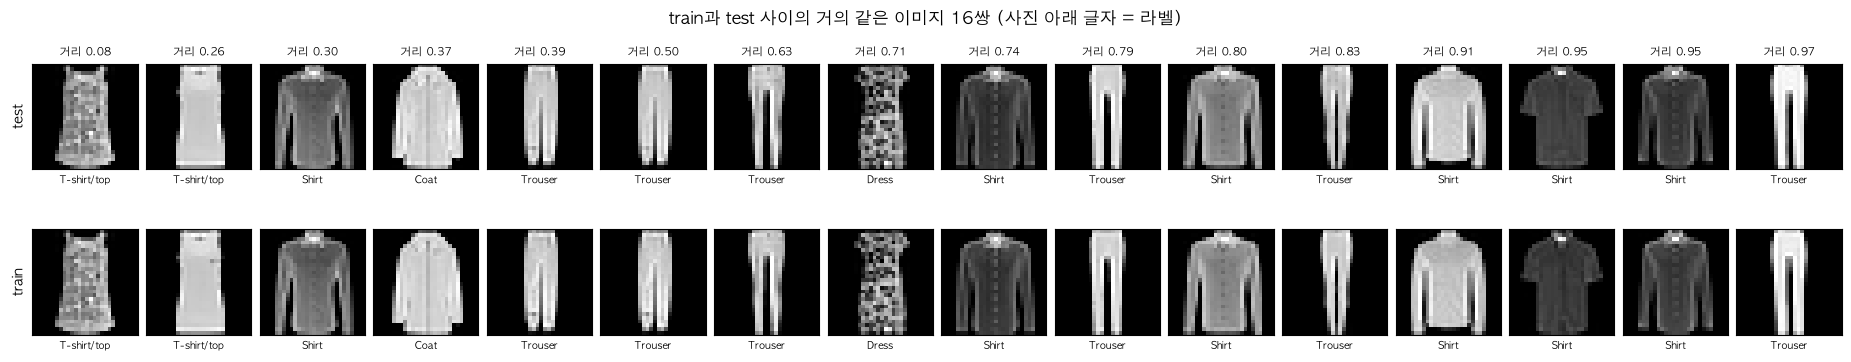

In [33]:
# 거리가 기준 미만인 train-test 쌍을 거리가 가까운 순서로 모두 표시 (위: test, 아래: 가장 가까운 train 이미지)
closest = torch.argsort(nearest_distance)[:near_count].tolist()

fig, axes = plt.subplots(2, len(closest), figsize=(len(closest) * 1.15, 3.6), layout='constrained')
for j, test_idx in enumerate(closest):
    train_idx = nearest_train_index[test_idx].item()
    axes[0, j].imshow(test_images[test_idx], cmap='gray', vmin=0, vmax=255)
    axes[0, j].set_title(f'거리 {nearest_distance[test_idx]:.2f}', fontsize=8)
    axes[0, j].set_xlabel(CLASS_NAMES[test_labels[test_idx]], fontsize=7)
    axes[1, j].imshow(train_images[train_idx], cmap='gray', vmin=0, vmax=255)
    axes[1, j].set_xlabel(CLASS_NAMES[train_labels[train_idx]], fontsize=7)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
axes[0, 0].set_ylabel('test')
axes[1, 0].set_ylabel('train')
fig.suptitle(f'train과 test 사이의 거의 같은 이미지 {near_count}쌍 (사진 아래 글자 = 라벨)')
save_fig(fig, '4-1_near_duplicates')
plt.show()

**인사이트**
- 16쌍 모두 같은 상품 사진으로 보이며, train과 test의 라벨도 모두 같다.
- 클래스별로는 Shirt 6쌍, Trouser 6쌍, T-shirt/top 2쌍, Coat 1쌍, Dress 1쌍이다.
- 쌍끼리의 차이는 밝기나 일부 픽셀의 미세한 차이뿐이다. 같은 원본 사진을 조금 다르게 처리한 것으로 보인다.

**결론**
- 라벨이 서로 다른 중복은 없으므로, 중복 때문에 생기는 라벨 오류는 없다.
- 누수 규모가 작아 별도 처리 없이 진행한다.

### 4-2. 이상치 확인
- 클래스마다 평균 이미지에서 가장 먼(3-1에서 계산한 거리가 가장 큰) 이미지 8장을 본다.
- 목적: 라벨이 잘못 붙었거나 모양이 특이한 이미지를 찾아, 제거할지 정한다.

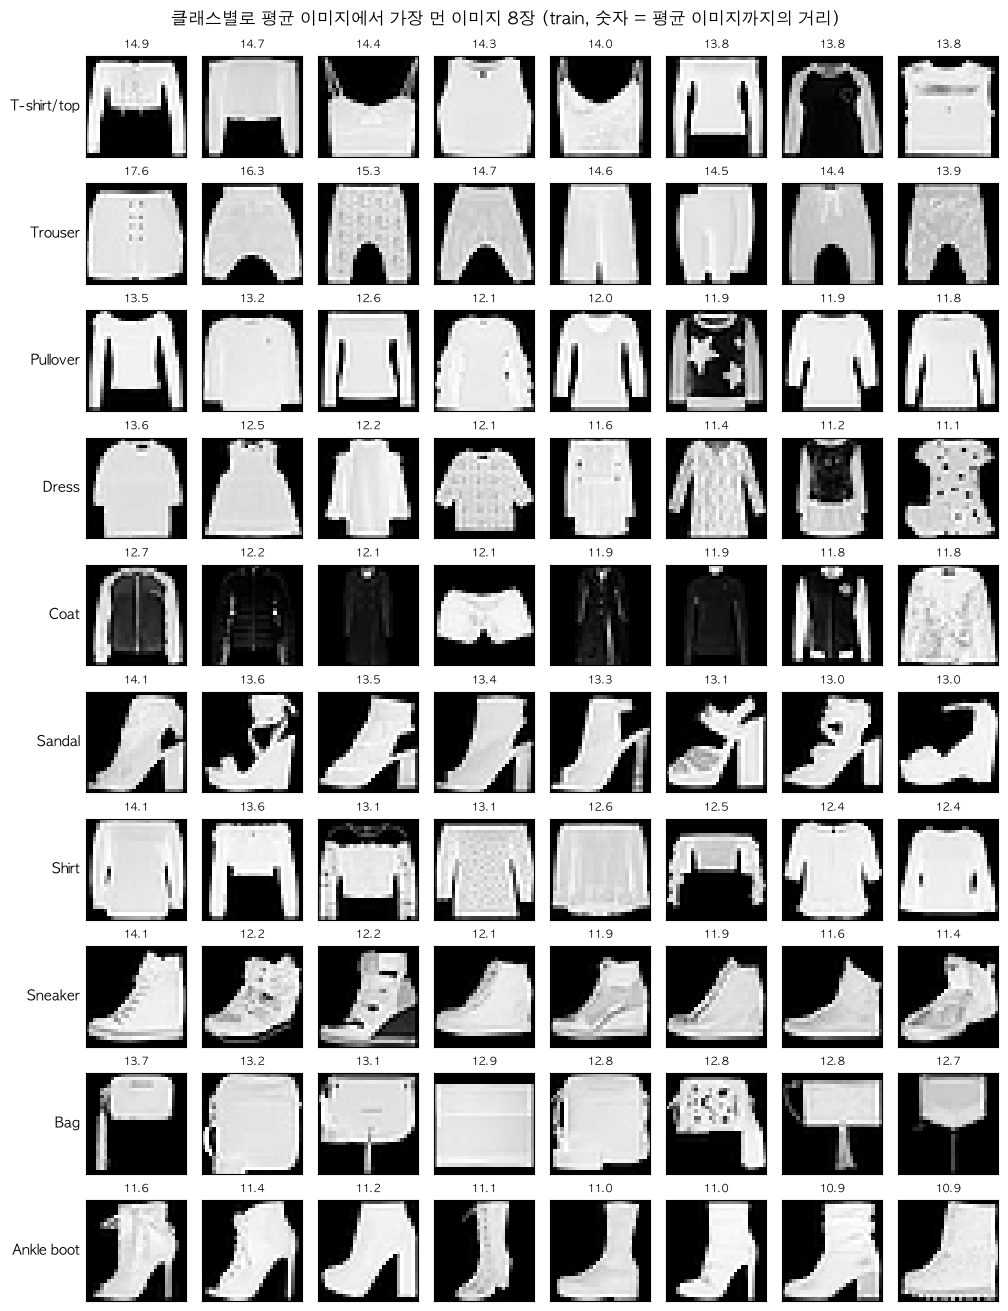

In [34]:
TOP_K = 8

fig, axes = plt.subplots(NUM_CLASSES, TOP_K, figsize=(TOP_K * 1.25, NUM_CLASSES * 1.3), layout='constrained')
for c in range(NUM_CLASSES):
    class_indices = torch.where(train_labels == c)[0]
    farthest = class_indices[torch.argsort(train_dist_to_mean[class_indices], descending=True)[:TOP_K]]
    for j, idx in enumerate(farthest.tolist()):
        axes[c, j].imshow(train_images[idx], cmap='gray', vmin=0, vmax=255)
        axes[c, j].set_title(f'{train_dist_to_mean[idx]:.1f}', fontsize=8)
        axes[c, j].set_xticks([])
        axes[c, j].set_yticks([])
    axes[c, 0].set_ylabel(CLASS_NAMES[c], rotation=0, ha='right', va='center', fontsize=10)
fig.suptitle('클래스별로 평균 이미지에서 가장 먼 이미지 8장 (train, 숫자 = 평균 이미지까지의 거리)')
save_fig(fig, '4-2_outliers')
plt.show()

**인사이트**
- 평균에서 먼 이미지는 대부분 라벨 오류가 아니라, 클래스 안에서 드문 스타일이다.
    - T-shirt/top: 크롭 상의, 민소매 상의, 긴소매 상의
    - Trouser: 반바지, 통이 넓은 바지 (긴 변을 28픽셀에 맞추면서 이미지를 넓게 채운 모양이 됨)
    - Sandal: 발목을 감싸는 굽 높은 샌들 (Ankle boot와 비슷해 보임)
    - Sneaker: 발목까지 오는 운동화 (Ankle boot와 비슷해 보임)
    - Bag: 손잡이가 옆에 달린 납작한 지갑형 가방
    - Coat: 아주 어두운 코트
- 일부는 라벨이 의심스럽다.
    - Coat 행의 4번째 이미지는 반바지처럼 보인다.
    - Dress 행의 1번째, 4번째 이미지는 상의처럼 보인다.
- 이 거리는 밝기와 면적에 크게 영향을 받는다. 그래서 아주 밝고 넓은 이미지나, 반대로 아주 어두운 이미지가 주로 뽑혔다.

**결론**
- 이상치 대부분이 정상적인 드문 스타일이므로 제거하지 않는다.
    - 이 거리를 기준으로 이미지를 지우면 드문 스타일이 사라져, 생성 결과의 다양성도 줄어든다.
- 라벨이 의심되는 이미지는 소수이고 자동으로 골라낼 기준도 없으므로, 그대로 둔다.
- Sandal과 Sneaker의 일부 스타일은 Ankle boot와 비슷하므로, 신발 클래스끼리 섞여 생성되는지 함께 확인한다.

## 5. 평가 기준선
- 생성 이미지의 점수를 해석하려면, 실제 이미지끼리 비교했을 때의 점수(기준선)를 먼저 알아야 한다.
- 사전 준비: 터미널에서 `uv add "torchmetrics[image]"`로 의존성을 추가했다. (`pyproject.toml`과 `uv.lock`은 함께 커밋)

### 5-1. 실제 이미지끼리의 FID
- FID(Fréchet Inception Distance)는 두 이미지 묶음이 얼마나 비슷한지 나타내는 거리이다.
    - 이미지 분류 모델인 Inception에 이미지를 넣어, 이미지마다 2048차원 특징 벡터를 뽑는다.
    - 두 묶음의 특징 벡터 분포(평균과 공분산)가 얼마나 다른지 계산한다.
    - 0에 가까울수록 두 묶음이 비슷하다.
- Inception은 컬러(3채널) 이미지를 받으므로, 흑백 채널을 3번 복제해서 넣는다. 299x299 크기 조정은 모델 안에서 자동으로 한다.
- train에서 클래스마다 1,000장씩 뽑은 10,000장과 test 10,000장을 비교한다.
- 실행 시간: Apple GPU(mps)에서 약 4분 걸린다. CPU만 쓰면 30분 이상 걸릴 수 있다.

In [35]:
FID_BATCH_SIZE = 100  # mps에서 이보다 크게 잡으면 메모리가 부족해 오히려 크게 느려졌다

# torchmetrics FID와 같은 Inception 모델 (생성 모델을 평가할 때도 같은 설정을 써야 이 기준선과 비교할 수 있다)
inception = FrechetInceptionDistance(feature=2048).inception.to(DEVICE)


@torch.no_grad()
def extract_inception_features(images):
    """uint8 흑백 이미지 (N, 28, 28)를 3채널로 복제해 Inception 특징 (N, 2048)을 뽑는다."""
    features = []
    for start in range(0, len(images), FID_BATCH_SIZE):
        batch = images[start:start + FID_BATCH_SIZE].unsqueeze(1).repeat(1, 3, 1, 1)
        features.append(inception(batch.to(DEVICE)).cpu())
    return torch.cat(features)


def compute_fid(features_a, features_b):
    """두 특징 묶음의 평균과 공분산으로 FID를 계산한다 (torchmetrics의 compute()와 같은 공식)."""
    a, b = features_a.double(), features_b.double()
    mean_term = (a.mean(dim=0) - b.mean(dim=0)).square().sum()
    cov_a, cov_b = torch.cov(a.T), torch.cov(b.T)
    cov_term = cov_a.trace() + cov_b.trace() - 2 * torch.linalg.eigvals(cov_a @ cov_b).sqrt().real.sum()
    return (mean_term + cov_term).item()


# 특징은 한 번만 뽑고, 전체와 클래스별 비교에 나눠서 재사용
rng = np.random.default_rng(SEED)
fid_train_index = np.concatenate([rng.choice(torch.where(train_labels == c)[0].numpy(), size=1000, replace=False)
                                  for c in range(NUM_CLASSES)])
fid_train_labels = train_labels[fid_train_index]
train_features = extract_inception_features(train_images[fid_train_index])
test_features = extract_inception_features(test_images)

rows = [['전체 (10개 클래스)', '10,000', '10,000', f'{compute_fid(train_features, test_features):.2f}']]
# 표본 수가 FID에 주는 영향을 보기 위해, 전체에서 1,000장씩만 뽑아서도 계산
small_train = rng.choice(len(train_features), size=1000, replace=False)
small_test = rng.choice(len(test_features), size=1000, replace=False)
rows.append(['전체 (10개 클래스)', '1,000', '1,000',
             f'{compute_fid(train_features[small_train], test_features[small_test]):.2f}'])
for c, name in enumerate(CLASS_NAMES):
    fid_value = compute_fid(train_features[fid_train_labels == c], test_features[test_labels == c])
    rows.append([name, '1,000', '1,000', f'{fid_value:.2f}'])
show_table(['비교 대상', 'train 이미지 수', 'test 이미지 수', '실제 이미지끼리의 FID'], rows)

| 비교 대상 | train 이미지 수 | test 이미지 수 | 실제 이미지끼리의 FID |
| --- | --- | --- | --- |
| 전체 (10개 클래스) | 10,000 | 10,000 | 2.52 |
| 전체 (10개 클래스) | 1,000 | 1,000 | 22.64 |
| T-shirt/top | 1,000 | 1,000 | 17.57 |
| Trouser | 1,000 | 1,000 | 10.31 |
| Pullover | 1,000 | 1,000 | 16.41 |
| Dress | 1,000 | 1,000 | 16.86 |
| Coat | 1,000 | 1,000 | 16.17 |
| Sandal | 1,000 | 1,000 | 16.81 |
| Shirt | 1,000 | 1,000 | 18.41 |
| Sneaker | 1,000 | 1,000 | 13.95 |
| Bag | 1,000 | 1,000 | 21.57 |
| Ankle boot | 1,000 | 1,000 | 13.31 |

**인사이트**
- 같은 분포에서 나온 실제 이미지끼리도 FID는 0이 아니다. 10,000장끼리 비교하면 2.52이다.
- 같은 전체 데이터라도 1,000장끼리 비교하면 22.64로 크게 올라간다.
    - FID는 표본 수가 적을수록 값이 커진다. 적은 표본으로는 평균과 공분산을 정확히 추정하기 어렵기 때문이다.
    - 그래서 표본 수가 다른 FID끼리는 비교할 수 없다.
- 클래스별 FID(각 1,000장)는 10.31(Trouser)~21.57(Bag)이다.
    - 모양이 단순한 Trouser, Ankle boot, Sneaker는 낮다.
    - 다양성이 큰 Bag, Shirt, T-shirt/top은 높다.

**결론**
- 생성 모델 평가의 기준선을 다음과 같이 정한다.
    - 전체: 생성 이미지 10,000장(클래스당 1,000장)과 test 10,000장을 비교한다. 기준선은 2.52이다.
    - 클래스별: 클래스당 생성 이미지 1,000장과 test 1,000장을 비교하고, 이 표의 클래스별 값을 기준선으로 쓴다.
- 생성 모델의 FID가 기준선에 가까울수록, 실제 데이터와 구분하기 어려운 이미지를 만든다는 뜻이다.
- 생성 이미지도 이 셀과 같은 방식으로 계산해야 기준선과 비교할 수 있다.
    - torchmetrics의 Inception 2048차원 특징을 쓰고, 흑백 채널을 3번 복제하고, 0~255 정수(uint8)로 넣는다.
    - Tanh 출력([-1, 1])은 `((x + 1) / 2 * 255).round().to(torch.uint8)`로 0~255 정수로 바꿔서 넣는다.

### 5-2. 판정용 분류기
- 실제 이미지로 간단한 합성곱 신경망(CNN, Convolutional Neural Network) 분류기를 학습한다.
- 나중에 생성 이미지를 이 분류기에 넣어, 요청한 라벨대로 생성되었는지 판정한다.
- 입력 범위는 Generator 출력과 같은 [-1, 1]로 맞춘다. 그래서 생성 이미지를 변환 없이 그대로 넣을 수 있다.
- 에폭(epoch)은 학습 데이터 전체를 한 번 다 보는 것을 말한다. 30에폭 학습하고, 가중치를 `RESULT_DIR`에 저장한다.

In [36]:
class FashionClassifier(nn.Module):
    """생성 이미지의 클래스를 판정할 간단한 합성곱 신경망. 입력: [-1, 1] 범위의 (N, 1, 28, 28) 이미지"""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),  # 28x28 -> 14x14
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),  # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, NUM_CLASSES),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


CLASSIFIER_EPOCHS = 30
CLASSIFIER_BATCH_SIZE = 128
CLASSIFIER_PATH = os.path.join(RESULT_DIR, 'fashion_classifier.pt')

# Generator의 Tanh 출력과 같은 [-1, 1] 범위로 변환
train_inputs = ((train_float - 0.5) / 0.5).unsqueeze(1).to(DEVICE)
train_targets = train_labels.to(DEVICE)

torch.manual_seed(SEED)
classifier = FashionClassifier().to(DEVICE)
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(1, CLASSIFIER_EPOCHS + 1):
    classifier.train()
    permutation = torch.randperm(len(train_inputs)).to(DEVICE)  # 에폭마다 학습 순서를 섞는다
    total_loss, total_correct = 0.0, 0
    for start in range(0, len(train_inputs), CLASSIFIER_BATCH_SIZE):
        batch_index = permutation[start:start + CLASSIFIER_BATCH_SIZE]
        inputs, targets = train_inputs[batch_index], train_targets[batch_index]
        logits = classifier(inputs)
        loss = loss_fn(logits, targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(batch_index)
        total_correct += (logits.argmax(dim=1) == targets).sum().item()
    print(f'에폭 {epoch:2d}/{CLASSIFIER_EPOCHS} | 학습 손실 {total_loss / len(train_inputs):.4f} | '
          f'학습 정확도 {total_correct / len(train_inputs):.2%}')

torch.save(classifier.state_dict(), CLASSIFIER_PATH)
print(f'가중치 저장: {CLASSIFIER_PATH}')

에폭  1/30 | 학습 손실 0.4317 | 학습 정확도 84.35%
에폭  2/30 | 학습 손실 0.2807 | 학습 정확도 89.72%
에폭  3/30 | 학습 손실 0.2479 | 학습 정확도 90.97%
에폭  4/30 | 학습 손실 0.2219 | 학습 정확도 91.83%
에폭  5/30 | 학습 손실 0.2043 | 학습 정확도 92.55%
에폭  6/30 | 학습 손실 0.1892 | 학습 정확도 93.09%
에폭  7/30 | 학습 손실 0.1791 | 학습 정확도 93.33%
에폭  8/30 | 학습 손실 0.1645 | 학습 정확도 93.85%
에폭  9/30 | 학습 손실 0.1564 | 학습 정확도 94.22%
에폭 10/30 | 학습 손실 0.1475 | 학습 정확도 94.47%
에폭 11/30 | 학습 손실 0.1386 | 학습 정확도 94.83%
에폭 12/30 | 학습 손실 0.1304 | 학습 정확도 95.02%
에폭 13/30 | 학습 손실 0.1227 | 학습 정확도 95.36%
에폭 14/30 | 학습 손실 0.1191 | 학습 정확도 95.40%
에폭 15/30 | 학습 손실 0.1101 | 학습 정확도 95.91%
에폭 16/30 | 학습 손실 0.1030 | 학습 정확도 96.13%
에폭 17/30 | 학습 손실 0.0990 | 학습 정확도 96.36%
에폭 18/30 | 학습 손실 0.0941 | 학습 정확도 96.47%
에폭 19/30 | 학습 손실 0.0884 | 학습 정확도 96.60%
에폭 20/30 | 학습 손실 0.0843 | 학습 정확도 96.78%
에폭 21/30 | 학습 손실 0.0770 | 학습 정확도 97.07%
에폭 22/30 | 학습 손실 0.0759 | 학습 정확도 97.08%
에폭 23/30 | 학습 손실 0.0719 | 학습 정확도 97.36%
에폭 24/30 | 학습 손실 0.0702 | 학습 정확도 97.32%
에폭 25/30 | 학습 손실 0.0671 | 학습 정확도 97.45%


**인사이트**
- 학습 손실이 에폭마다 거의 꾸준히 줄었고, 30에폭 후 학습 정확도는 97.86%이다.
- 학습 정확도가 오르는 폭은 점점 작아진다. 10에폭 94.47%, 20에폭 96.78%, 30에폭 97.86%로, 10에폭마다 2.31%p, 1.08%p 올랐다.

**결론**
- 판정용으로 쓸 만큼 학습되었다. test 정확도는 다음 셀에서 확인한다.
- 실험 노트북에서는 저장한 가중치 파일(`results/eda_raewoo/fashion_classifier.pt`)을 불러와 생성 이미지를 판정한다.
    - 불러올 때는 이 셀의 `FashionClassifier` 클래스 정의가 함께 필요하다.

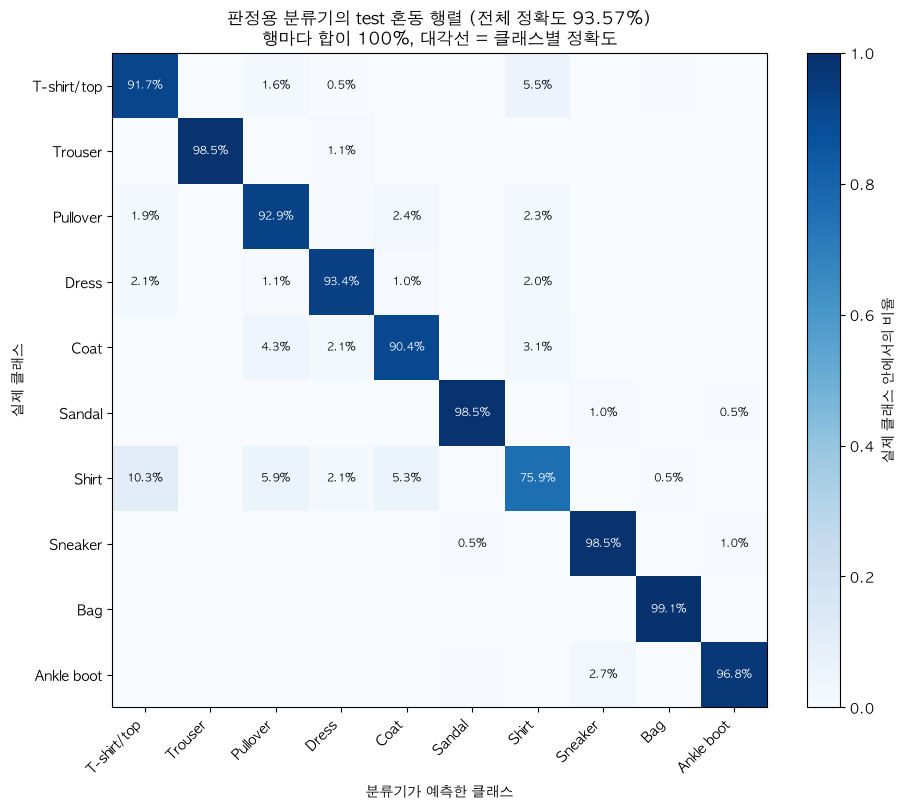

In [37]:
# test 이미지 예측 (학습 때와 같은 [-1, 1] 범위로 변환)
test_inputs = ((test_float - 0.5) / 0.5).unsqueeze(1).to(DEVICE)
classifier.eval()
with torch.no_grad():
    test_pred = torch.cat([classifier(test_inputs[start:start + 1000]).argmax(dim=1).cpu()
                           for start in range(0, len(test_inputs), 1000)])
accuracy = (test_pred == test_labels).float().mean().item()

# 혼동 행렬: (실제 클래스, 예측 클래스) 조합마다 개수를 센 뒤, 행마다 비율로 바꾼다
confusion = torch.bincount(test_labels * NUM_CLASSES + test_pred, minlength=NUM_CLASSES ** 2)
confusion = confusion.reshape(NUM_CLASSES, NUM_CLASSES).float()
confusion_ratio = (confusion / confusion.sum(dim=1, keepdim=True)).numpy()

fig, ax = plt.subplots(figsize=(9.5, 8), layout='constrained')
image = ax.imshow(confusion_ratio, cmap='Blues', vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if confusion_ratio[i, j] >= 0.005:  # 0.5% 미만은 표시하지 않음
            text_color = 'white' if confusion_ratio[i, j] > 0.5 else 'black'
            ax.text(j, i, f'{confusion_ratio[i, j]:.1%}', ha='center', va='center', fontsize=8, color=text_color)
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
ax.set_xlabel('분류기가 예측한 클래스')
ax.set_ylabel('실제 클래스')
fig.colorbar(image, ax=ax, label='실제 클래스 안에서의 비율')
ax.set_title(f'판정용 분류기의 test 혼동 행렬 (전체 정확도 {accuracy:.2%})\n행마다 합이 100%, 대각선 = 클래스별 정확도')
save_fig(fig, '5-2_confusion_matrix')
plt.show()

**인사이트**
- test 전체 정확도는 93.57%이다.
    - 10에폭만 학습했을 때(92.71%)보다 0.86%p 높다.
    - 같은 구간에서 학습 정확도는 94.47%에서 97.86%로 3.39%p 올라, 학습 정확도와 test 정확도의 차이가 1.76%p에서 4.29%p로 벌어졌다. 늘린 에폭은 주로 train 데이터에 더 맞추는 데 쓰였다.
- 클래스별 정확도 차이가 크다.
    - 높은 클래스: Bag 99.1%, Trouser 98.5%, Sandal 98.5%, Sneaker 98.5%
    - 낮은 클래스: Shirt 75.9%, Coat 90.4%, T-shirt/top 91.7%
- Shirt를 가장 많이 틀린다.
    - 실제 Shirt의 10.3%를 T-shirt/top으로, 5.9%를 Pullover로, 5.3%를 Coat로 예측했다.
    - 반대 방향 혼동도 있다. 실제 T-shirt/top의 5.5%를 Shirt로 예측했다.
- 신발끼리도 일부 혼동한다. 실제 Ankle boot의 2.7%를 Sneaker로 예측했다.

**결론**
- 생성 이미지의 판정 정확도는 이 그림의 클래스별 정확도와 비교해야 한다.
    - 예를 들어 생성한 Shirt의 판정 정확도가 76% 근처라면, 실제 Shirt 수준으로 만든 것이다.
    - 판정 정확도가 실제보다 크게 낮은 클래스는, 조건 라벨을 제대로 반영하지 못한 클래스이다.
- Shirt와 다른 상의 클래스 사이의 혼동은 데이터 자체의 한계이기도 하다. 3번에서 정한 모니터링 클래스와 일치한다.

### 5-3. 실데이터 기준 통계 (선택)
- 생성 이미지와 비교할 기준으로, test 이미지의 통계를 클래스별로 정리한다.
    - 이미지 평균 밝기: 784개 픽셀 값의 평균
    - 비배경 픽셀 비율: 784개 픽셀 중 값이 0이 아닌 픽셀의 비율
- 생성 이미지로 같은 그림을 그려 겹쳐 보면, 형태가 뭉개졌는지와 생성 결과가 몇 가지 모양으로 몰렸는지(mode collapse, 모드 붕괴)를 점검할 수 있다.

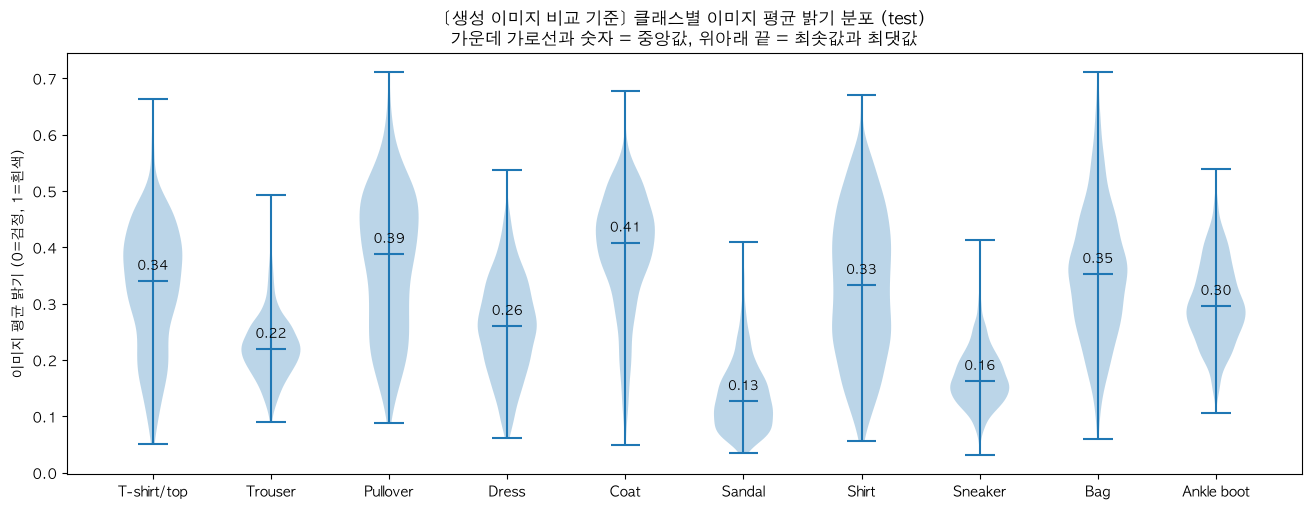

In [38]:
fig, ax = plt.subplots(figsize=(13, 5), layout='constrained')
ax.violinplot([test_brightness[test_labels == c].numpy() for c in range(NUM_CLASSES)], showmedians=True)
for x, c in enumerate(range(NUM_CLASSES), start=1):
    median = test_brightness[test_labels == c].median().item()
    ax.text(x, median + 0.02, f'{median:.2f}', ha='center', fontsize=9)
ax.set_xticks(range(1, NUM_CLASSES + 1), CLASS_NAMES)
ax.set_ylabel('이미지 평균 밝기 (0=검정, 1=흰색)')
ax.set_title('[생성 이미지 비교 기준] 클래스별 이미지 평균 밝기 분포 (test)\n'
             '가운데 가로선과 숫자 = 중앙값, 위아래 끝 = 최솟값과 최댓값')
save_fig(fig, '5-3_reference_brightness')
plt.show()

**인사이트**
- 클래스마다 평균 밝기의 중앙값과 퍼진 정도가 다르다.
    - Sandal(0.13)과 Sneaker(0.16)는 어둡다. 물체 면적이 작아 배경 비율이 높기 때문이다.
    - Coat(0.41)와 Pullover(0.39)는 밝은 편이다.
    - T-shirt/top, Pullover, Coat, Shirt, Bag은 아래위로 길게 퍼져 있다. 옷과 가방의 색이 다양하다는 뜻이다.

**결론**
- 생성 이미지의 클래스별 평균 밝기 분포를 같은 방식으로 그려 이 그림과 겹쳐 본다.
    - 중앙값이 실제보다 크게 높으면, 배경이 회색으로 떴거나 물체 색이 틀어진 것이다.
    - 분포 폭이 눈에 띄게 좁으면, 비슷한 밝기의 이미지만 만드는 모드 붕괴(mode collapse)를 의심한다.

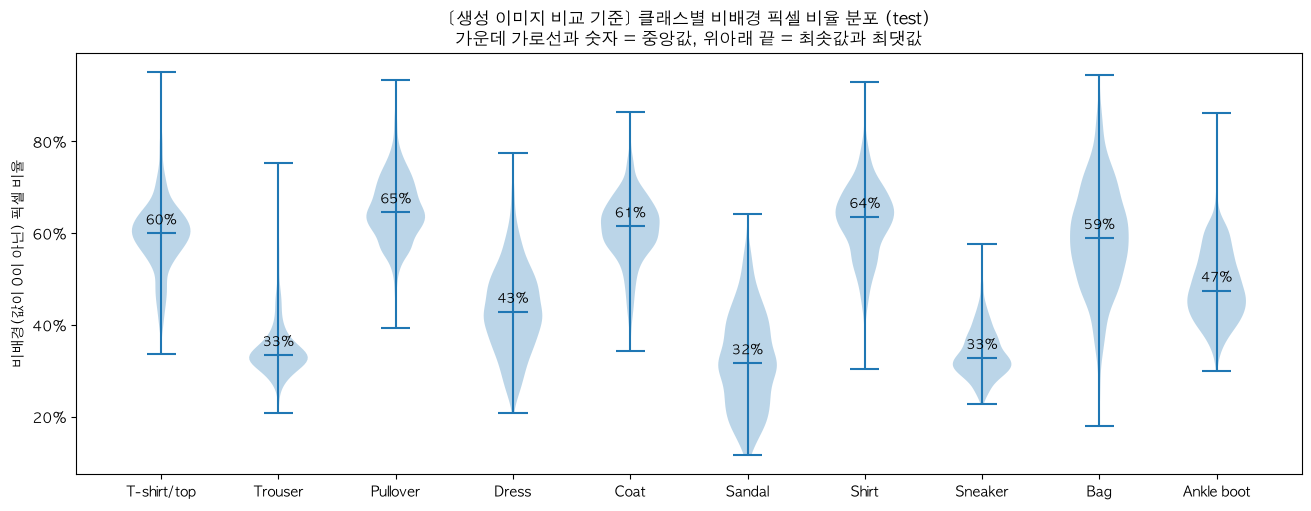

In [39]:
test_object_ratio = (test_images > 0).float().mean(dim=(1, 2))

fig, ax = plt.subplots(figsize=(13, 5), layout='constrained')
ax.violinplot([test_object_ratio[test_labels == c].numpy() for c in range(NUM_CLASSES)], showmedians=True)
for x, c in enumerate(range(NUM_CLASSES), start=1):
    median = test_object_ratio[test_labels == c].median().item()
    ax.text(x, median + 0.02, f'{median:.0%}', ha='center', fontsize=9)
ax.set_xticks(range(1, NUM_CLASSES + 1), CLASS_NAMES)
ax.set_ylabel('비배경(값이 0이 아닌) 픽셀 비율')
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_title('[생성 이미지 비교 기준] 클래스별 비배경 픽셀 비율 분포 (test)\n'
             '가운데 가로선과 숫자 = 중앙값, 위아래 끝 = 최솟값과 최댓값')
save_fig(fig, '5-3_reference_object_ratio')
plt.show()

**인사이트**
- 비배경 픽셀 비율의 중앙값은 상의 클래스가 60~65%로 높고, Trouser, Sandal, Sneaker는 32~33%로 낮다.
- 가장 높은 이미지도 약 95% 수준이다. 실제 이미지에는 검은 배경이 항상 남아 있다.

**결론**
- 생성 이미지는 uint8(0~255 정수)로 바꾼 뒤 같은 방식으로 비율을 계산해 이 그림과 비교한다.
    - 비율이 실제보다 높으면, 배경이 정확히 0이 되지 않고 희미한 값이 남은 것이다. (배경이 회색으로 뜨는 현상)
    - 비율이 실제보다 낮으면, 물체가 가늘거나 일부가 빠진 형태로 생성된 것이다.
    - 분포 폭이 눈에 띄게 좁으면, 모드 붕괴를 의심한다.

## 6. EDA 결론
- 1~5번의 결과를 항목별 결정 사항으로 정리한다. 괄호 안 번호는 근거가 된 셀의 번호이다.

| 항목 | 결정 | 근거 |
| --- | --- | --- |
| 정규화 | `v2.ToImage()` → `v2.ToDtype(torch.float32, scale=True)` → `v2.Normalize(mean=[0.5], std=[0.5])`로 [-1, 1]로 변환하고, Generator 마지막 활성화 함수는 Tanh를 사용 | 픽셀 값이 0~255를 끝까지 쓰고, 변환 후 정확히 -1~1이 됨 (1-2) |
| 데이터 증강: 회전 | 사용하지 않음 | 모든 물체가 똑바로 세워진 자세로 정렬됨 (1-3, 2-1) |
| 데이터 증강: 크롭, 이동, 확대·축소 | 사용하지 않음 | 98.3%의 이미지에서 물체가 이미지 끝에서 끝까지 꽉 차 있고, 무게중심이 클래스마다 거의 고정됨 (2-3) |
| 데이터 증강: 좌우 반전 | 사용하지 않음 | 신발 세 클래스는 앞코가 왼쪽을 향하도록 정렬됨, 좌우 비대칭 점수 0.29~0.49 (2-2) |
| 데이터 증강: 밝기 조절 | 사용하지 않음 | 약 92%의 이미지가 0~255 범위를 꽉 채우고, 배경은 항상 정확히 0 (1-2) |
| 라벨 샘플링 | 10개 클래스를 균등하게 샘플링 | 클래스별 train 6,000장, test 1,000장으로 완전히 균등 (1-1) |
| 데이터 정제 | 중복 이미지와 이상치 모두 제거하지 않음 | 거의 같은 이미지는 test의 0.16%(16장)뿐이고 라벨도 같음 (4-1), 이상치 대부분이 정상적인 드문 스타일 (4-2) |
| 평가 기준 분포 | test 10,000장 | train과 test의 분포가 같음 (1-1, 1-3) |
| 평가 방법: FID | 전체는 생성 10,000장과 test 10,000장을 비교 (기준선 2.52), 클래스별로는 1,000장끼리 비교 (기준선 10.31~21.57) | 표본 수에 따라 FID가 크게 달라지므로 표본 수를 맞춰야 함 (5-1) |
| 평가 방법: 판정용 분류기 | 저장한 분류기로 생성 이미지를 판정하고, 실제 test의 클래스별 정확도(75.9%~99.1%)와 비교 | 전체 정확도 93.57%, Shirt가 가장 낮음 (5-2) |
| 평가 방법: 보조 통계 | 클래스별 평균 밝기와 비배경 픽셀 비율 분포를 test와 겹쳐 비교 | 배경이 회색으로 뜨는 현상, 형태 뭉개짐, 모드 붕괴 점검 (5-3) |
| 모니터링 클래스 | Shirt, Pullover, Coat, T-shirt/top (서로 섞일 위험), Bag (다양성이 가장 큼), Sandal, Sneaker, Ankle boot (신발끼리 일부 혼동) | 평균 모양 유사도 0.95~0.99 (3-2), 주성분 분석에서 겹침 (3-2), 분류기 혼동 (5-2), 거리 분포 (3-1) |

**추가 실험 후보**
- Discriminator가 학습 데이터에 과적합하는 징후가 보이면, 실제 이미지와 생성 이미지 모두에 같은 증강을 적용하는 방법을 실험한다.
    - 대칭 클래스(옷, 가방)에 한한 좌우 반전, 또는 DiffAugment(Discriminator 입력에 미분 가능한 증강을 적용하는 방법)
- 생성 결과에서 상의 클래스끼리 섞이는 문제가 크면, 판정용 분류기의 클래스별 정확도를 기준으로 조건 라벨을 넣는 방식(라벨 임베딩 크기, 라벨을 넣는 위치)을 바꿔 가며 비교한다.